<a href="https://www.kaggle.com/code/lalit7881/telecom-customer-churn-eda-80?scriptVersionId=359909431" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/alipakzad/telecom-customer-churn/IT_customer_churn.csv


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/alipakzad/telecom-customer-churn/IT_customer_churn.csv")

In [3]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.tail()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,Male,0,No,No,66,Yes,No,Fiber optic,Yes,No,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(22)

In [9]:
df.dtypes

gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [10]:
df.shape

(7043, 20)

In [11]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [12]:
df.nunique()

gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

## EDA

TELCO CUSTOMER CHURN - EXPLORATORY DATA ANALYSIS
Dataset shape: (7021, 21)
Total customers: 7,021
Duplicate rows removed: 22

Missing values after cleaning:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Churn distribution:
Churn
No     5164
Yes    1857
Name: count, dtype: int64

NUMERICAL SUMMARY


,tenure,MonthlyCharges,TotalCharges
count,7021.00,7021.00,7021.00
mean,32.47,64.85,2288.96
std,24.53,30.07,2265.32
min,0.00,18.25,18.80
25%,9.00,35.75,411.15
50%,29.00,70.40,1403.88
75%,55.00,89.90,3801.70
max,72.00,118.75,8684.80



CATEGORICAL SUMMARY


,count,unique,top,freq
gender,7021,2,Male,3541
Partner,7021,2,No,3619
Dependents,7021,2,No,4911
PhoneService,7021,2,Yes,6339
MultipleLines,7021,3,No,3368
InternetService,7021,3,Fiber optic,3090
OnlineSecurity,7021,3,No,3490
OnlineBackup,7021,3,No,3080
DeviceProtection,7021,3,No,3087
TechSupport,7021,3,No,3465


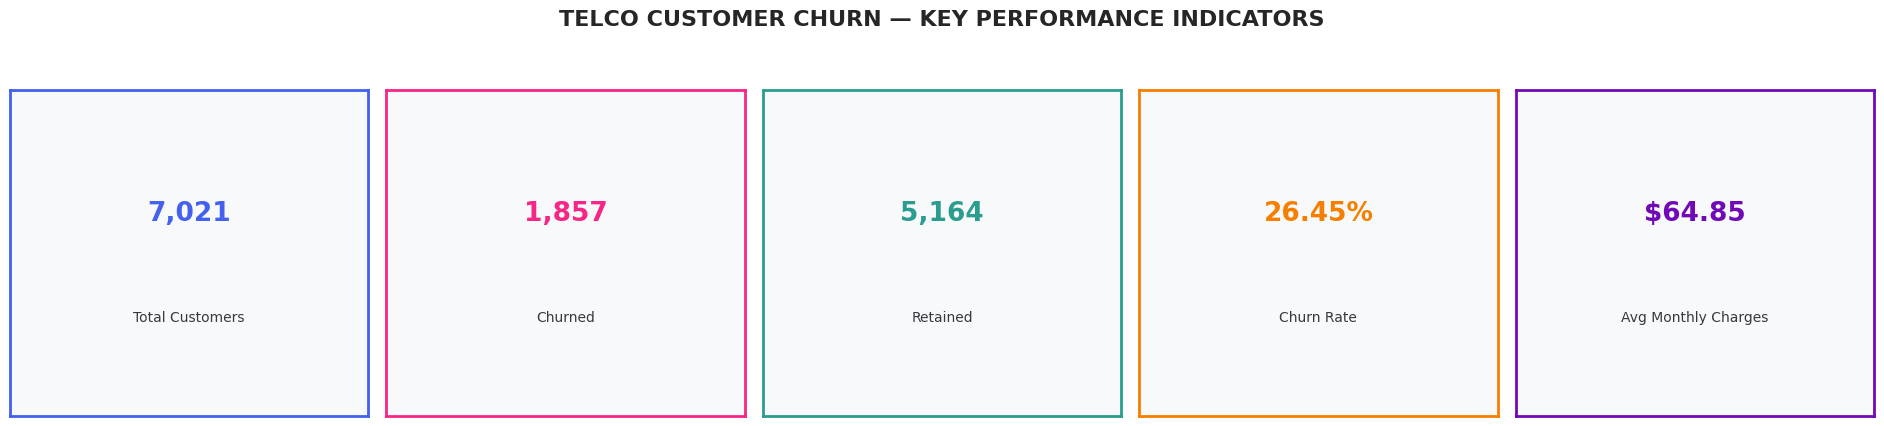

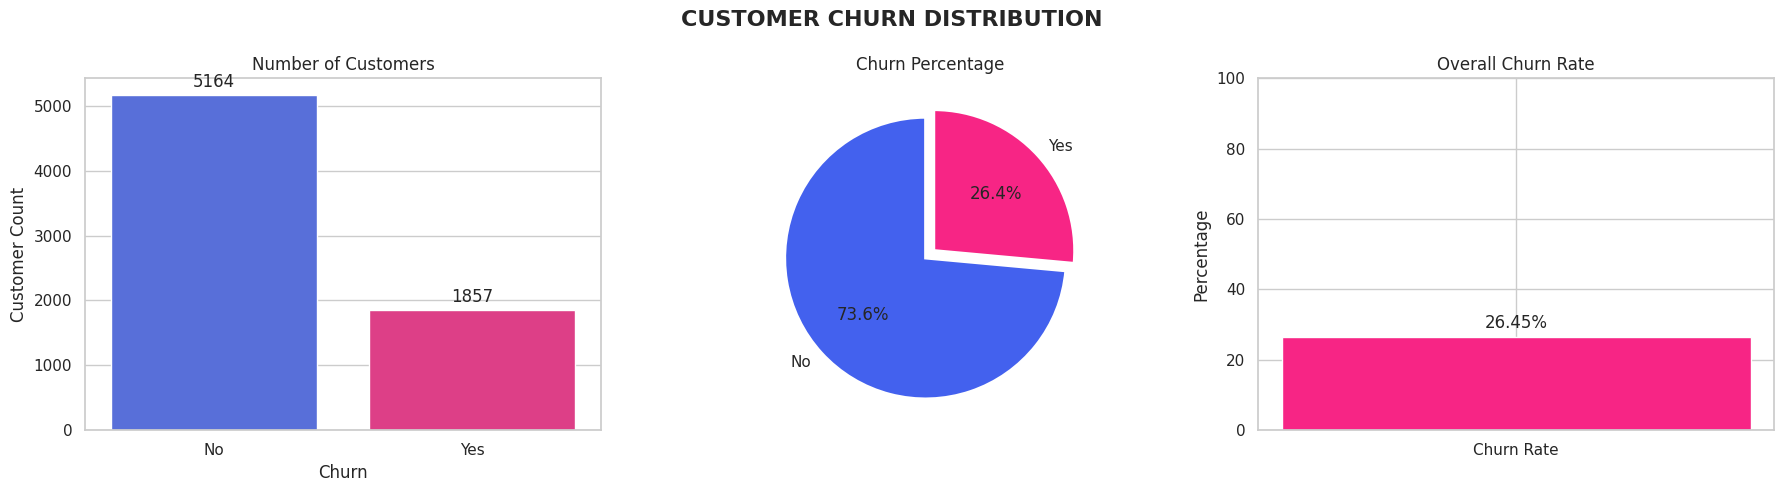

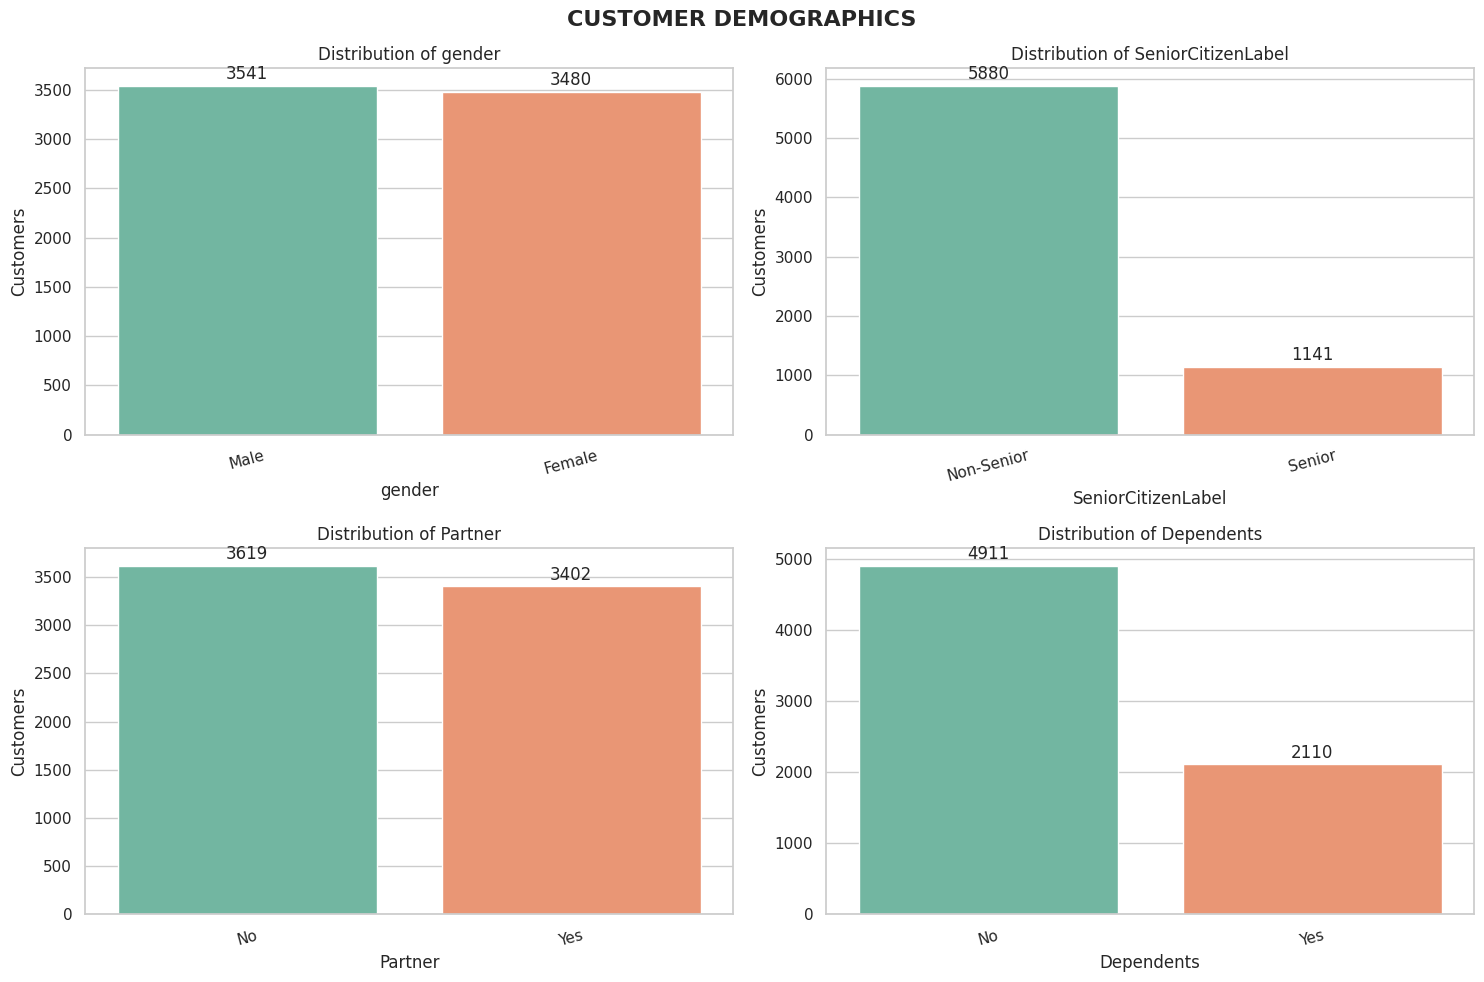

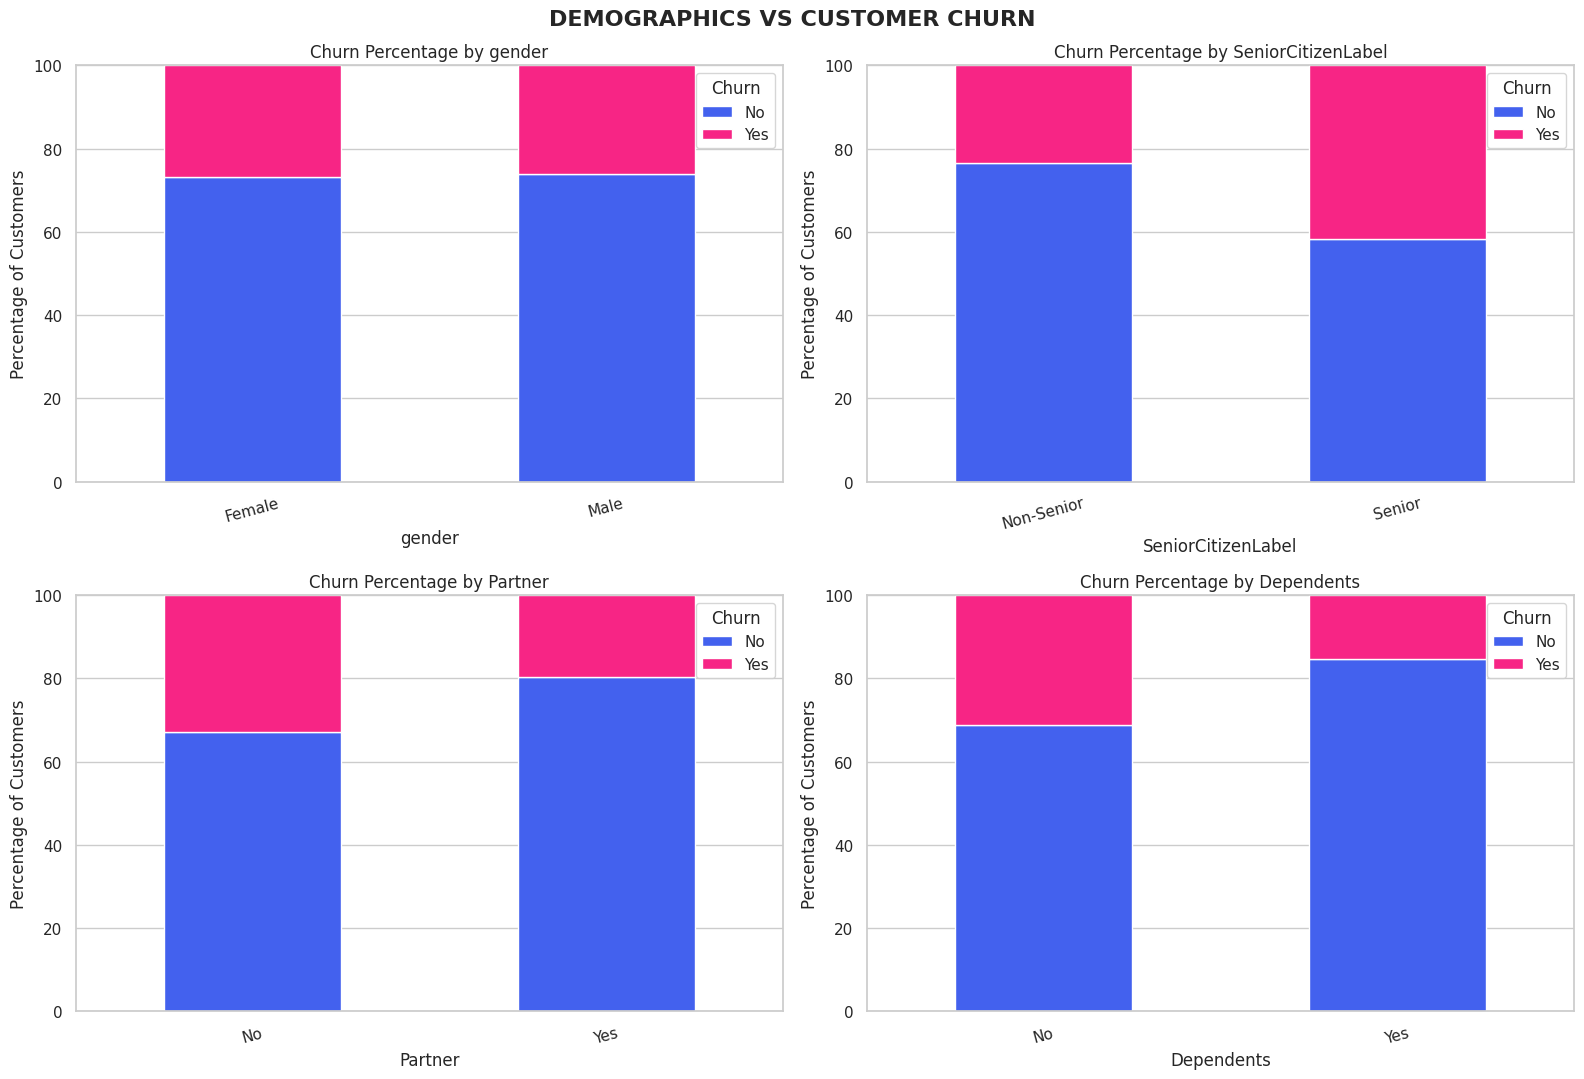

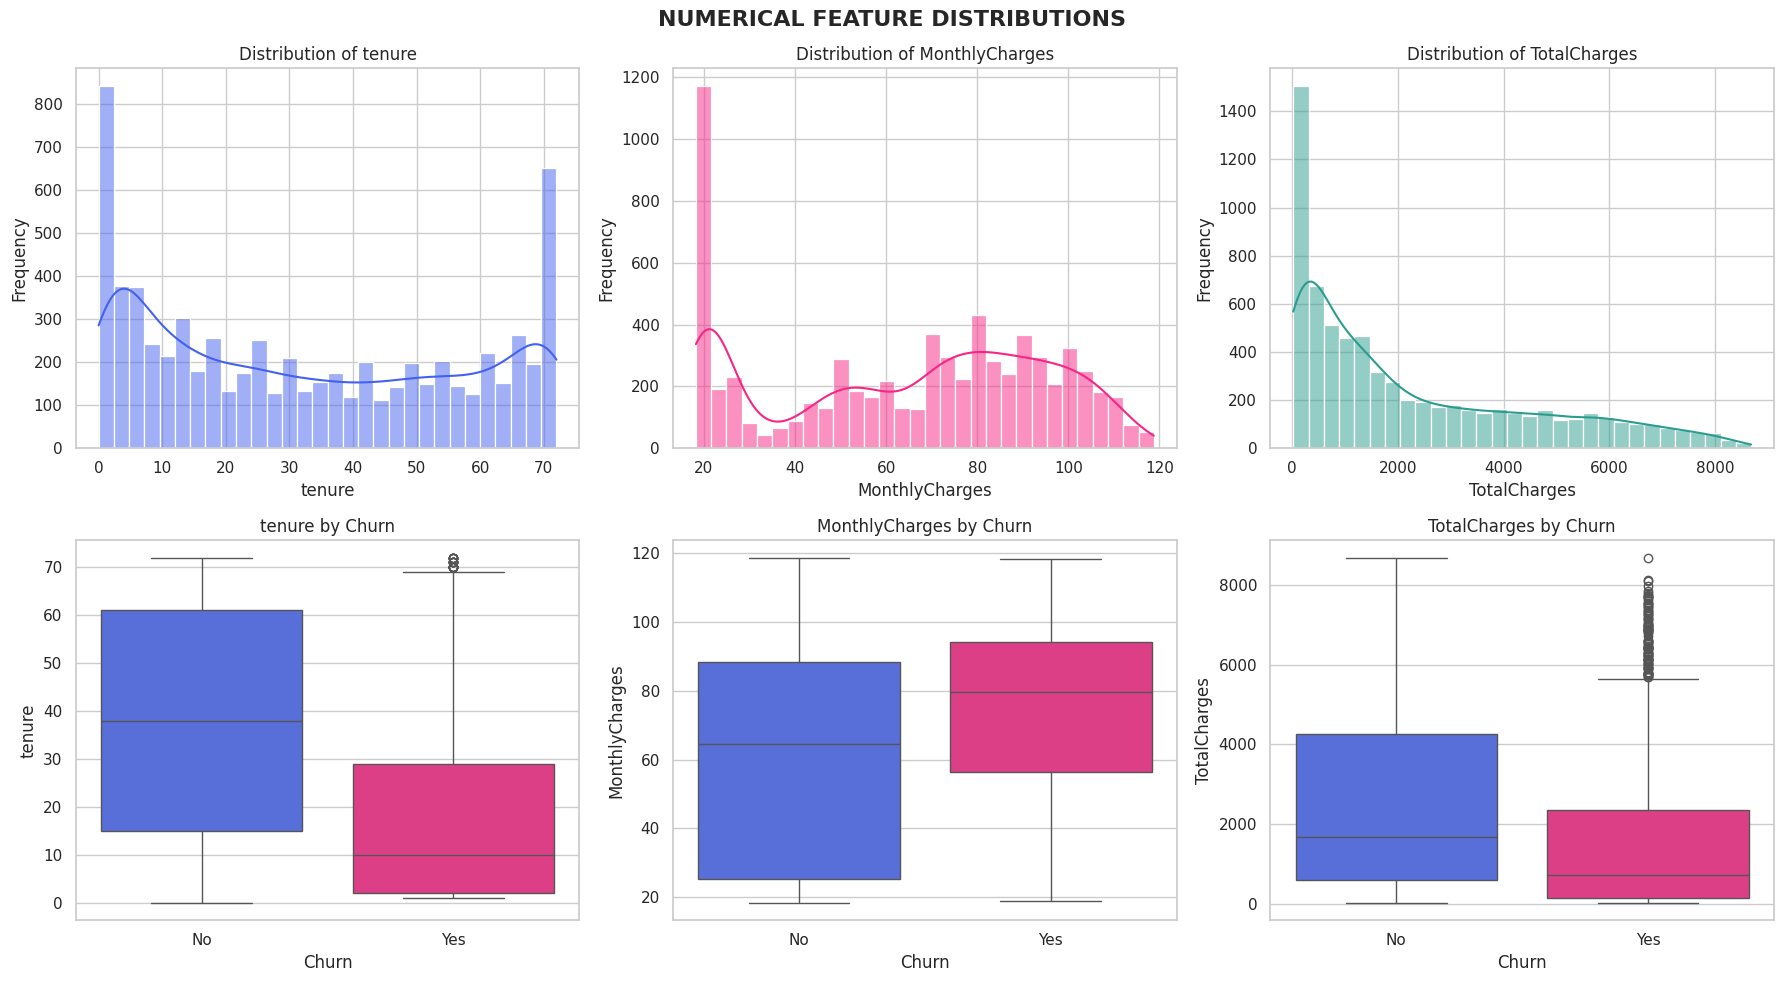

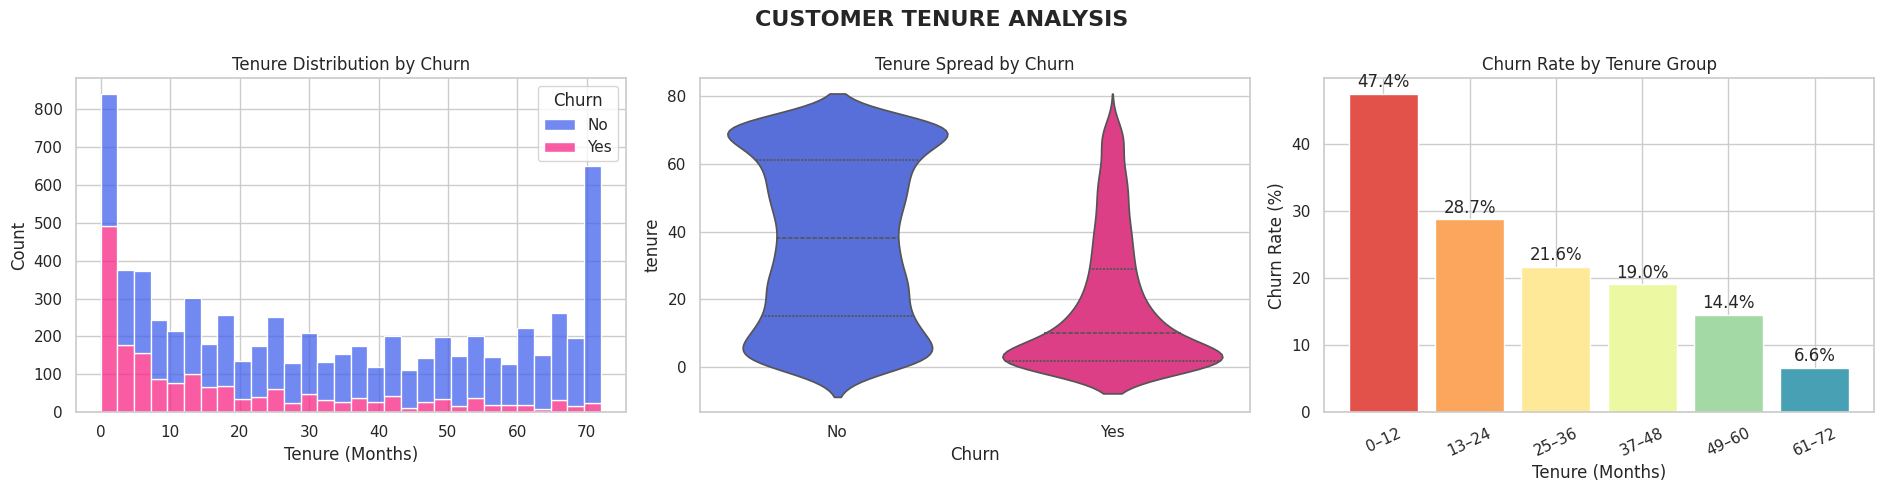

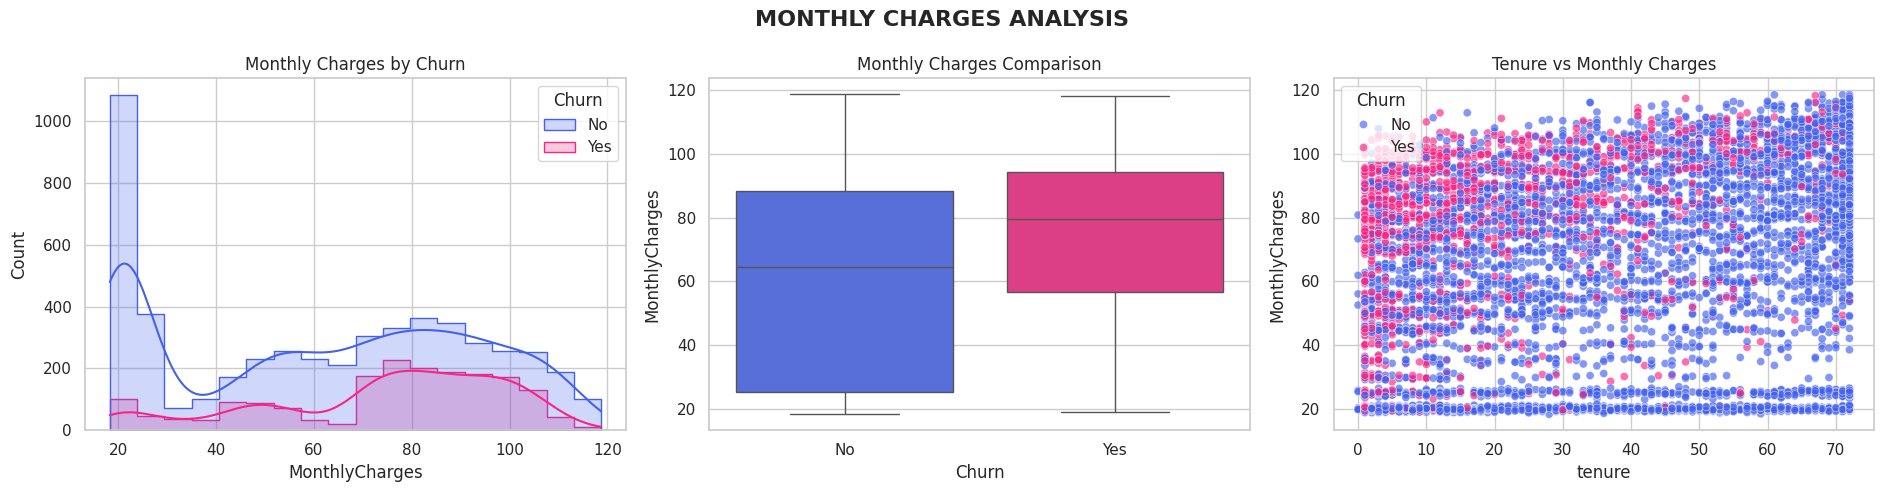

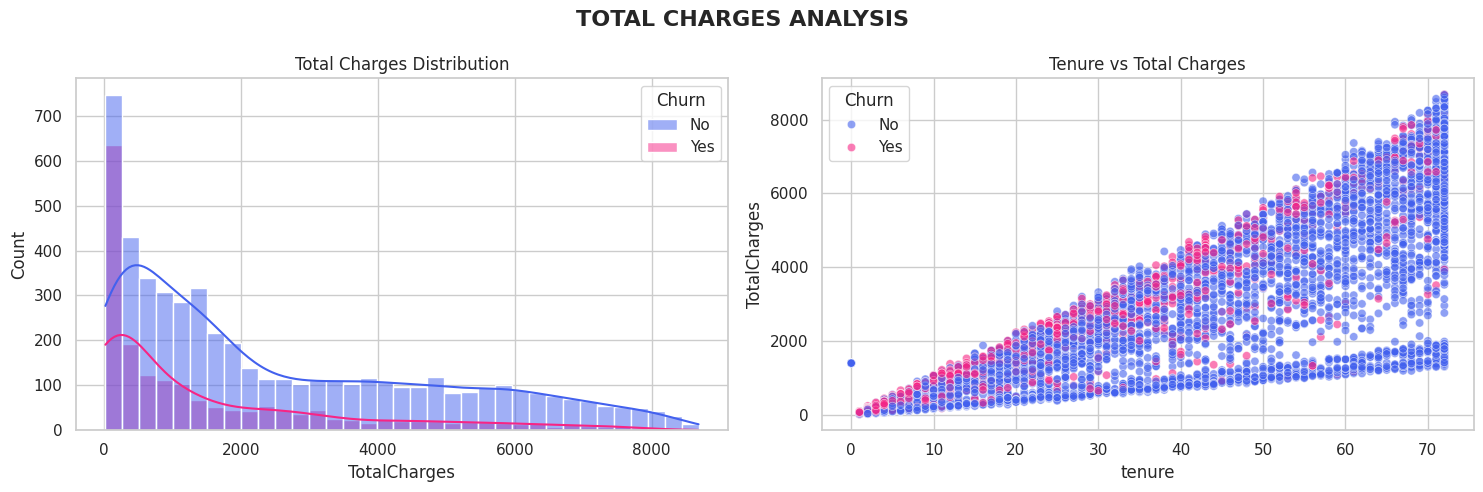

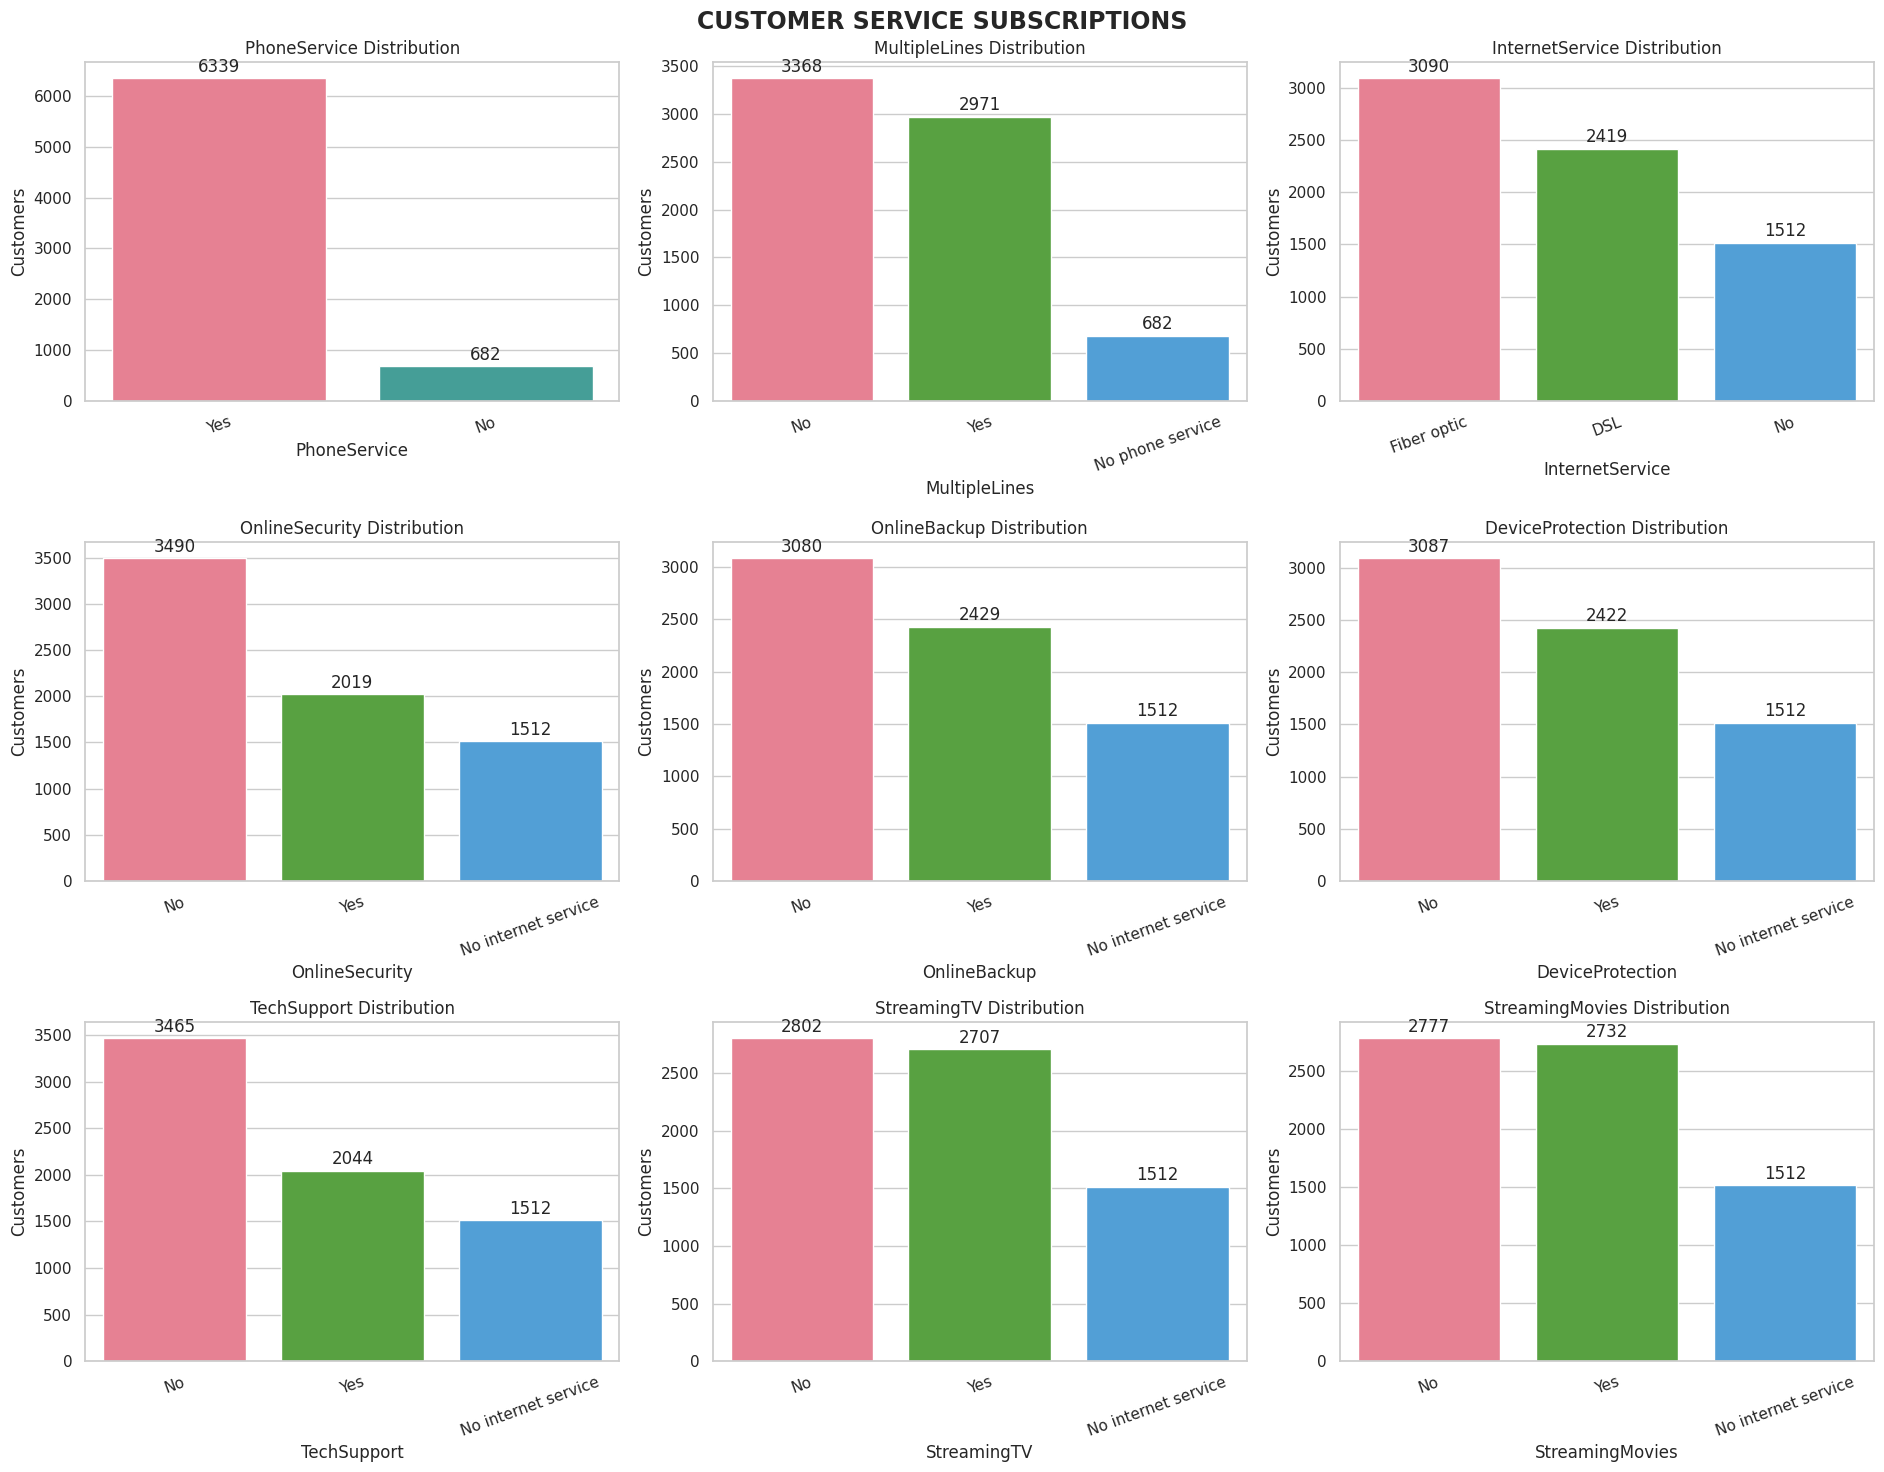

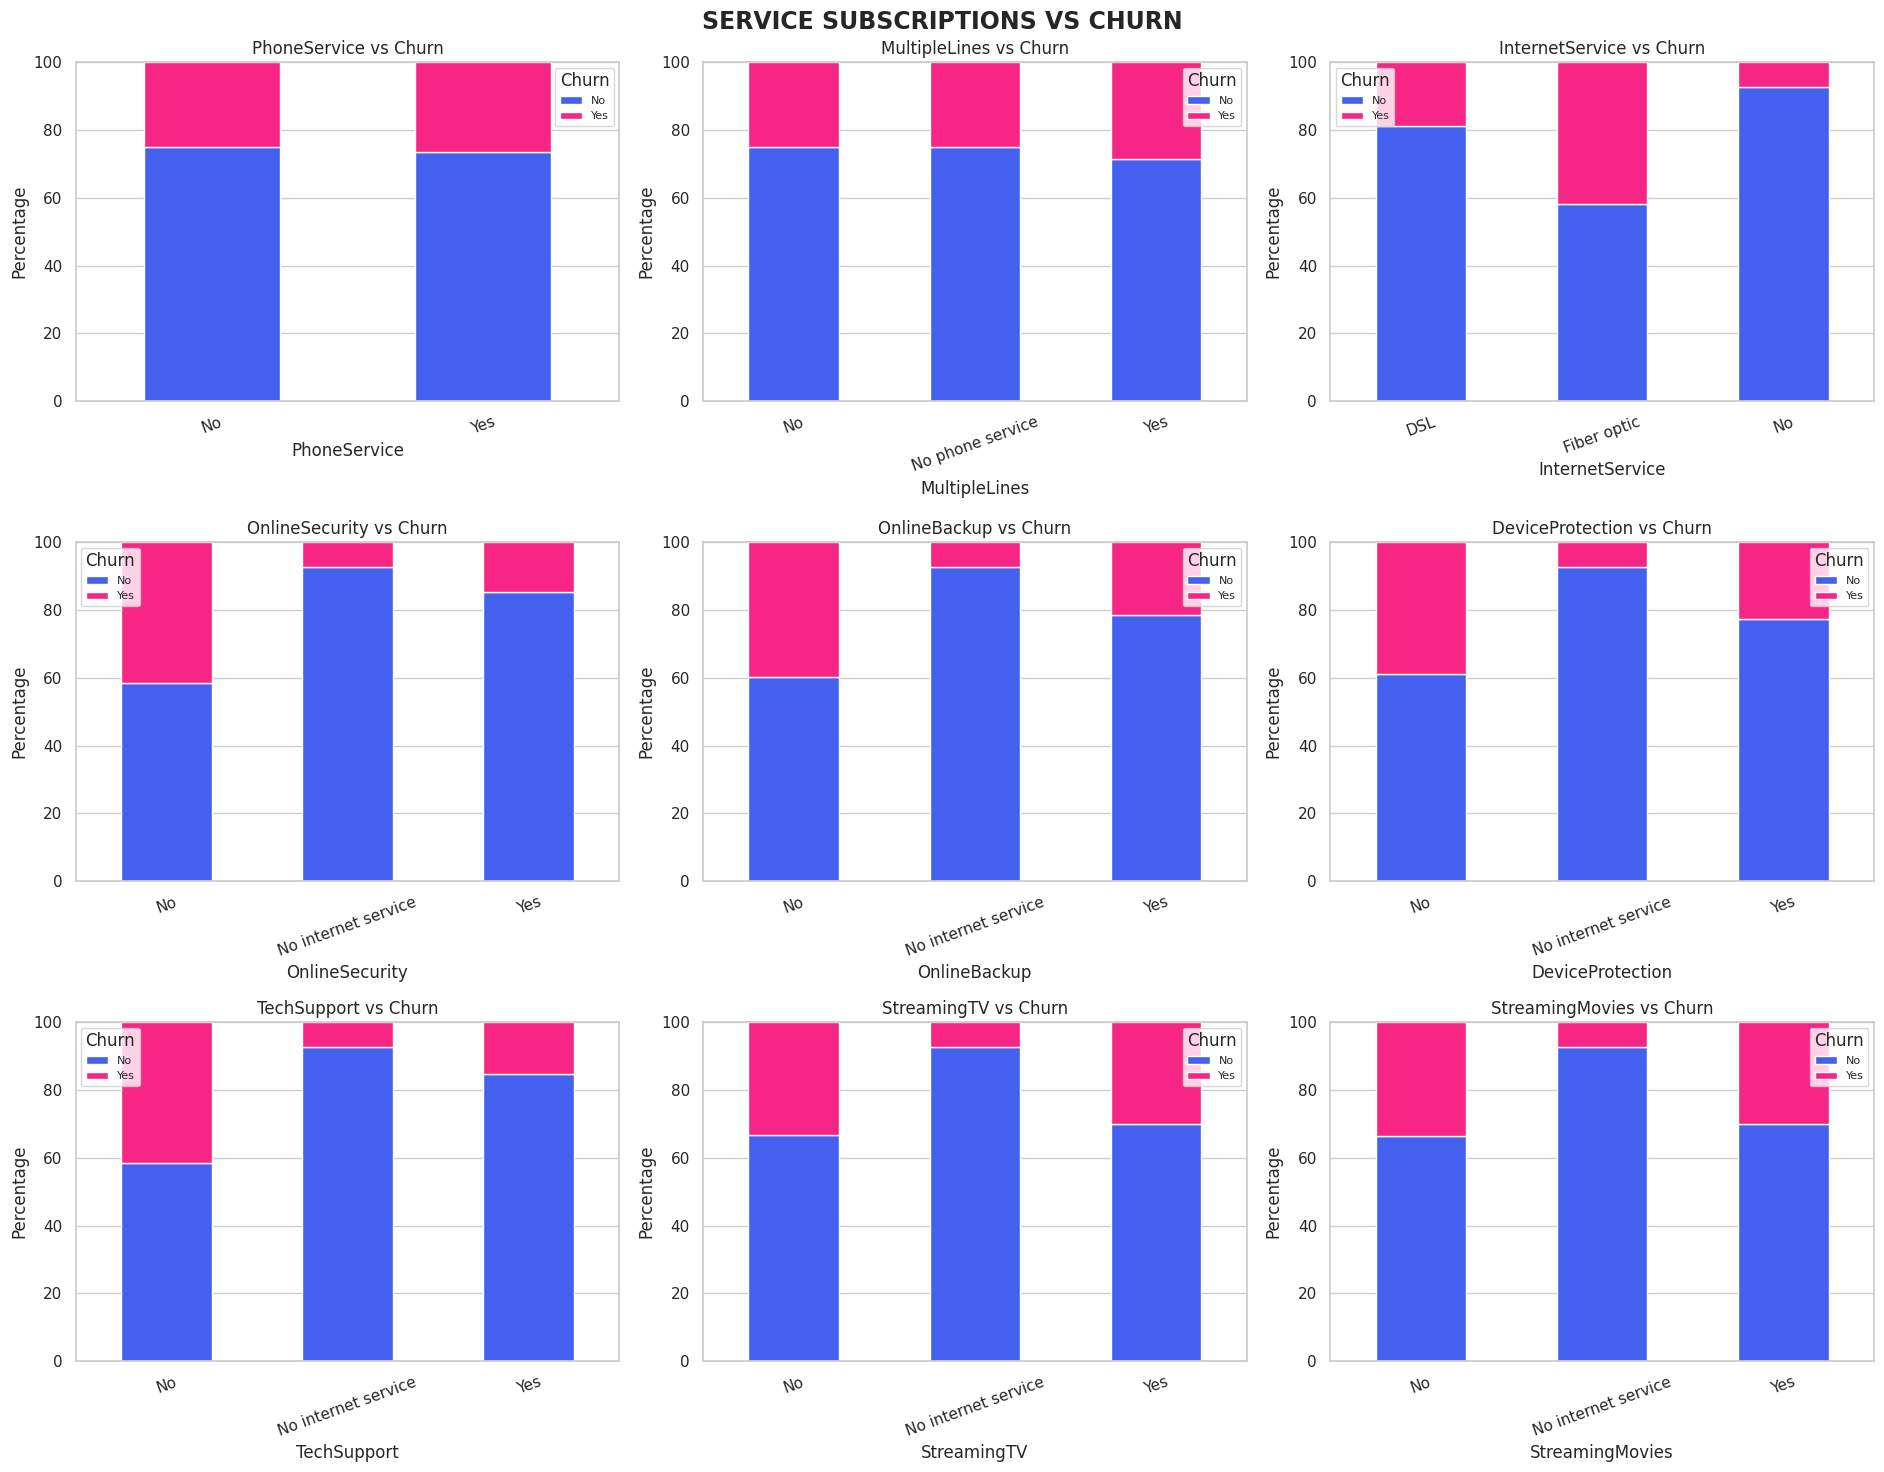

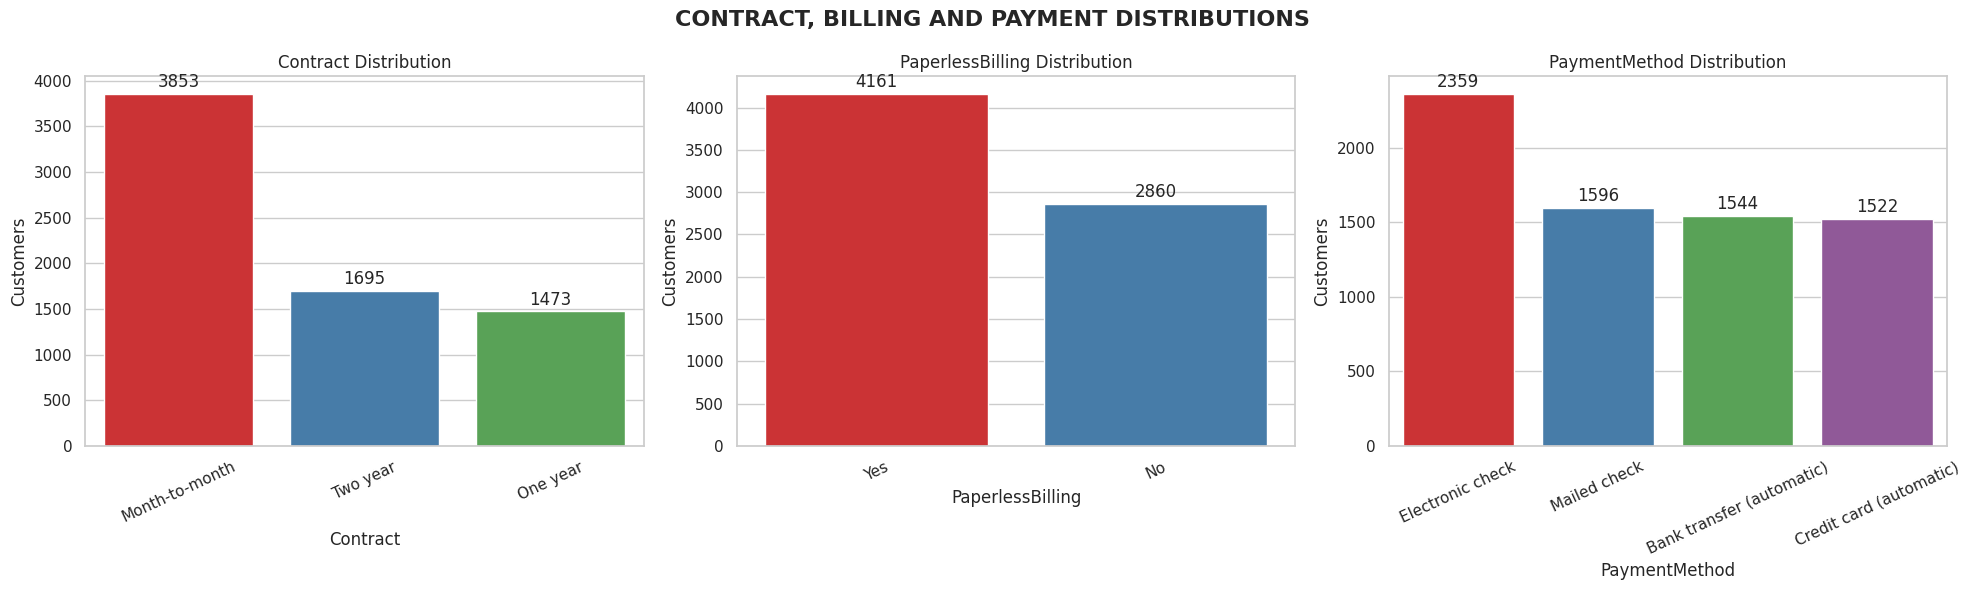

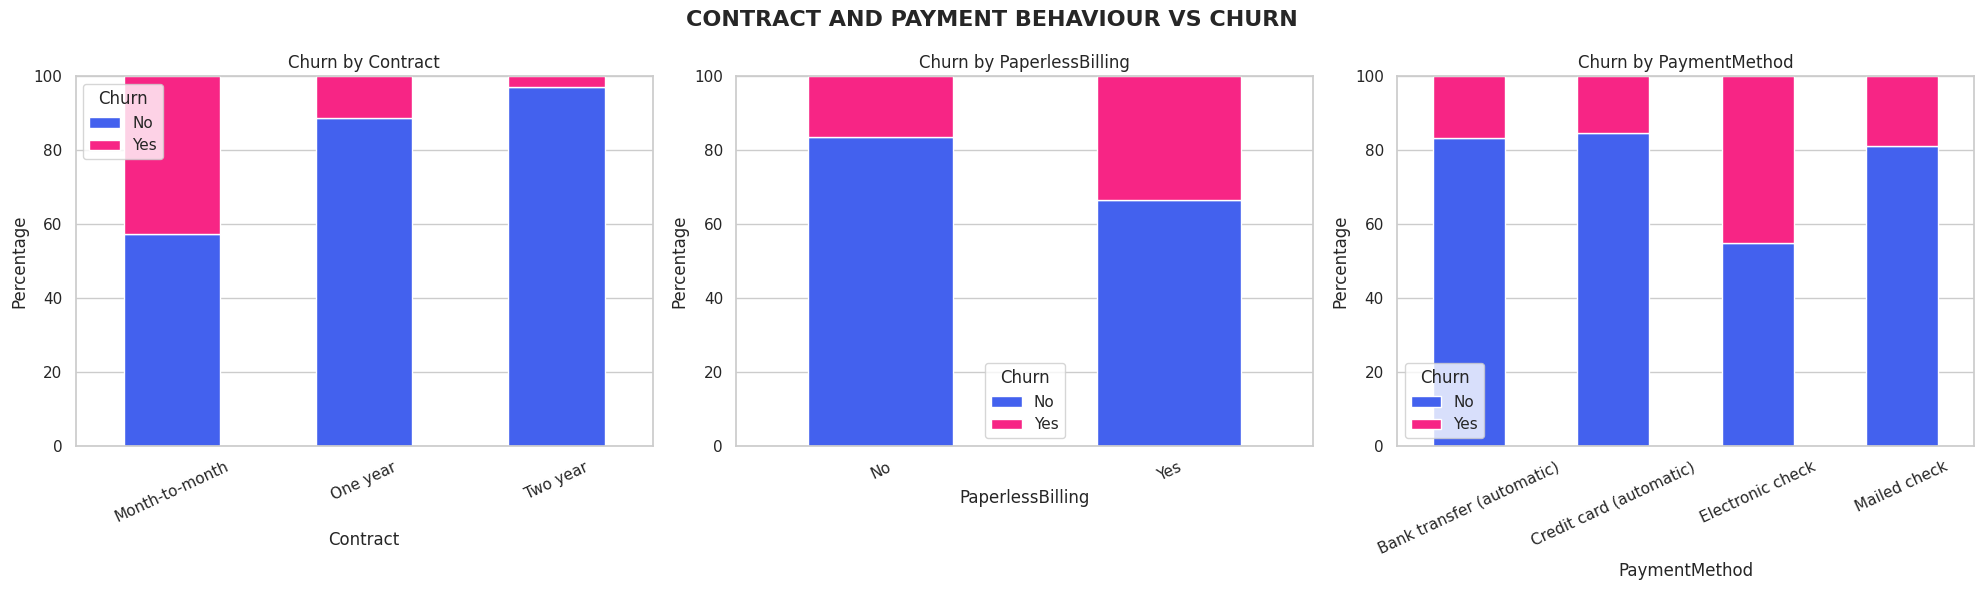

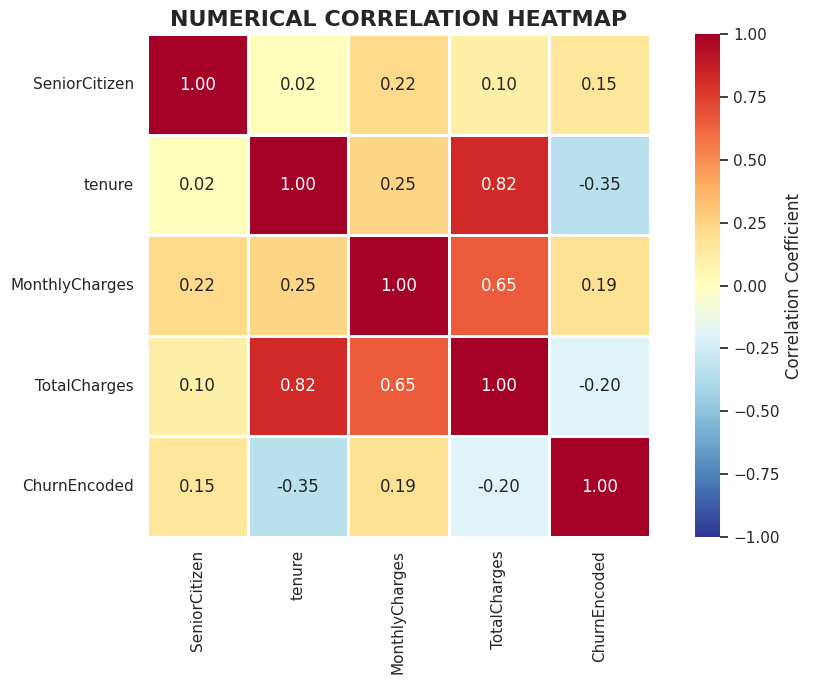

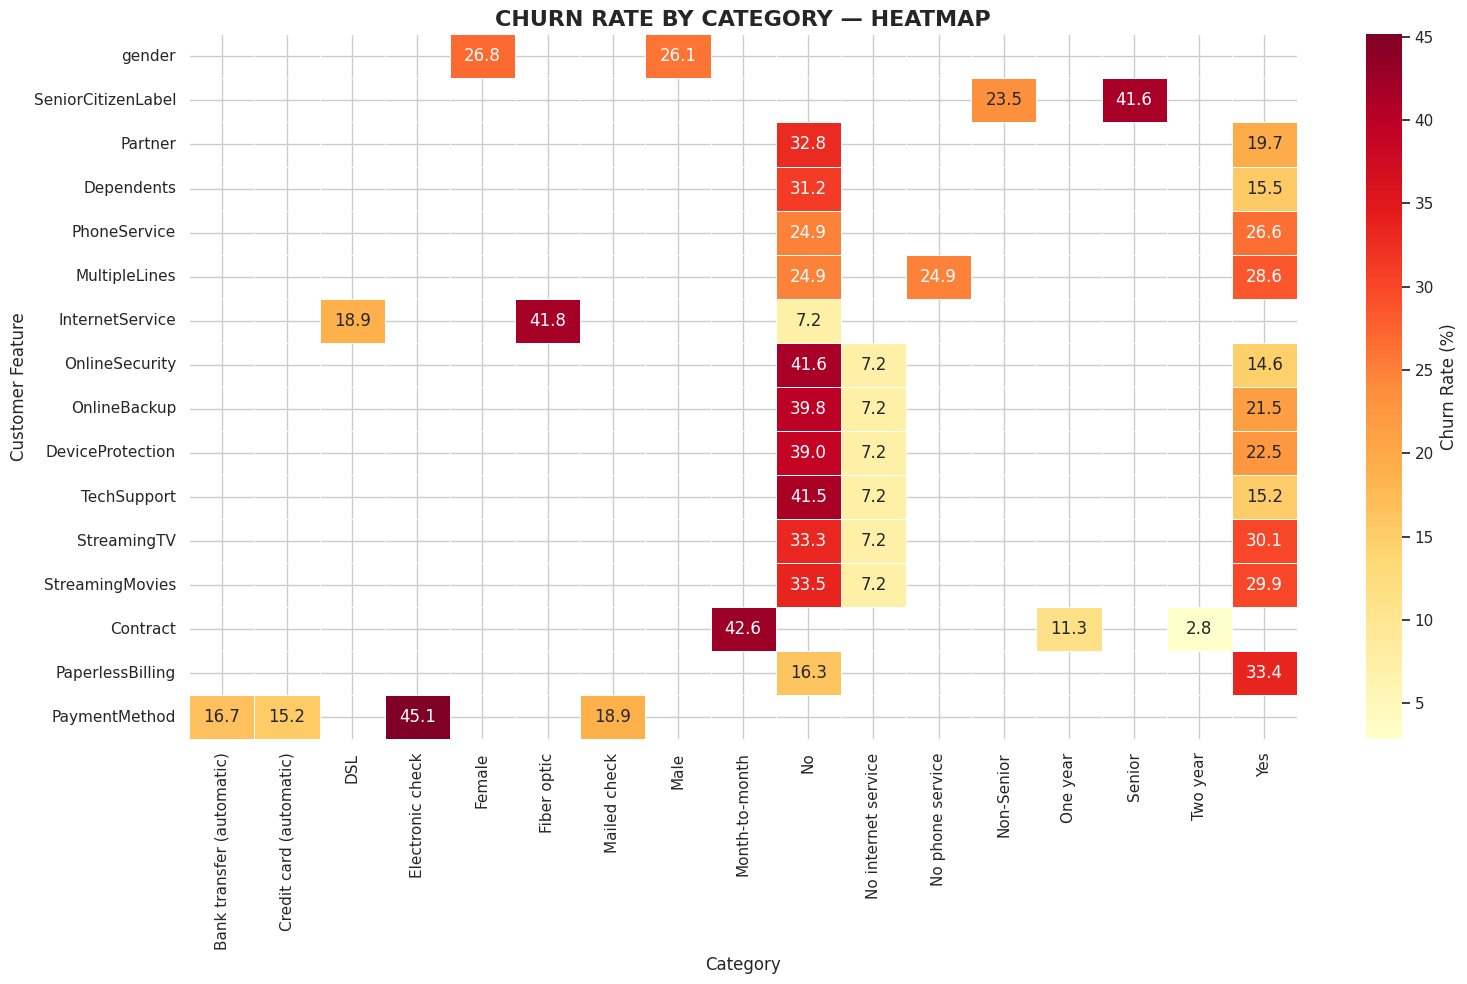

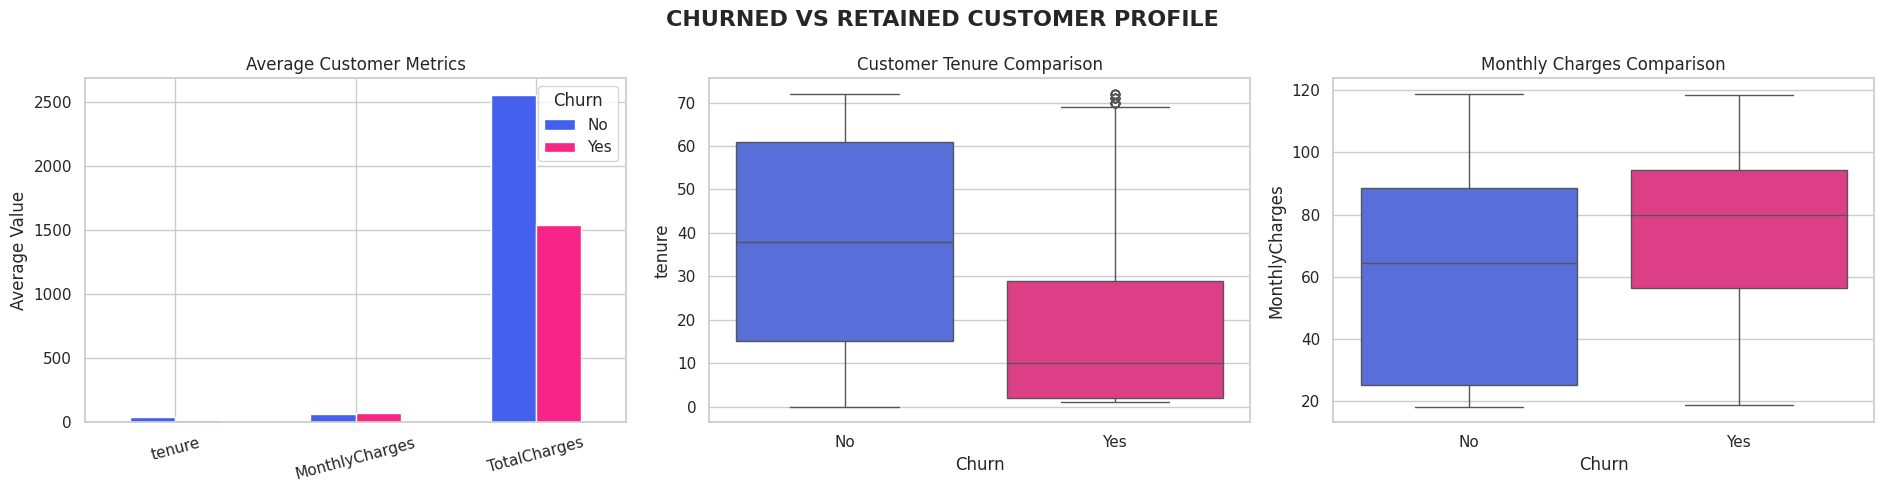

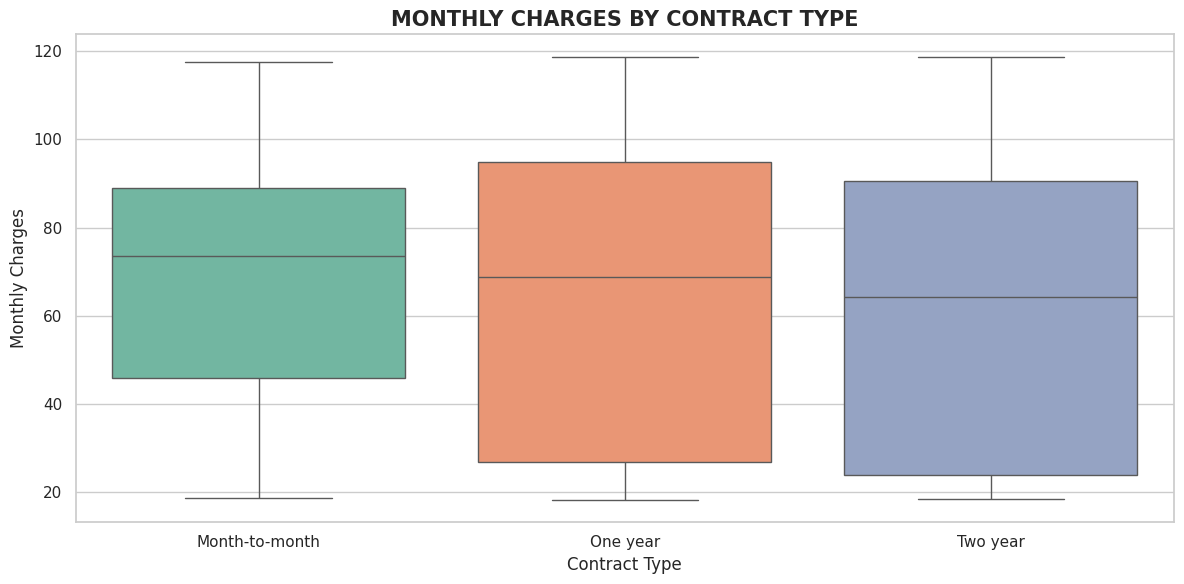

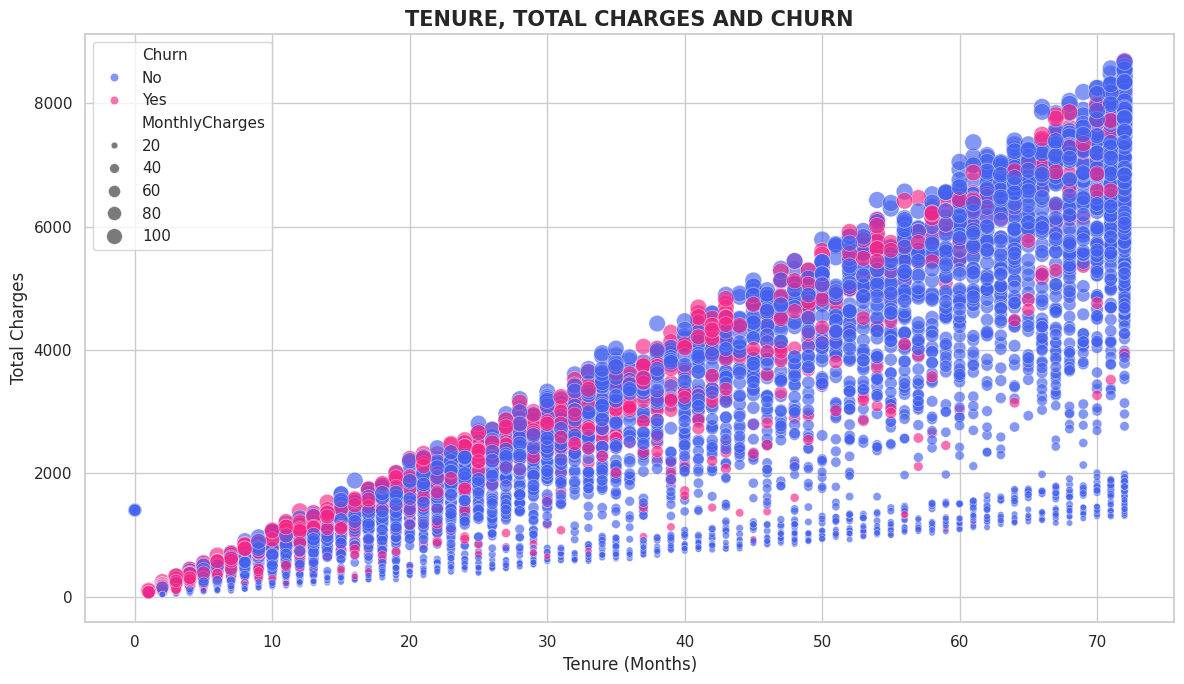

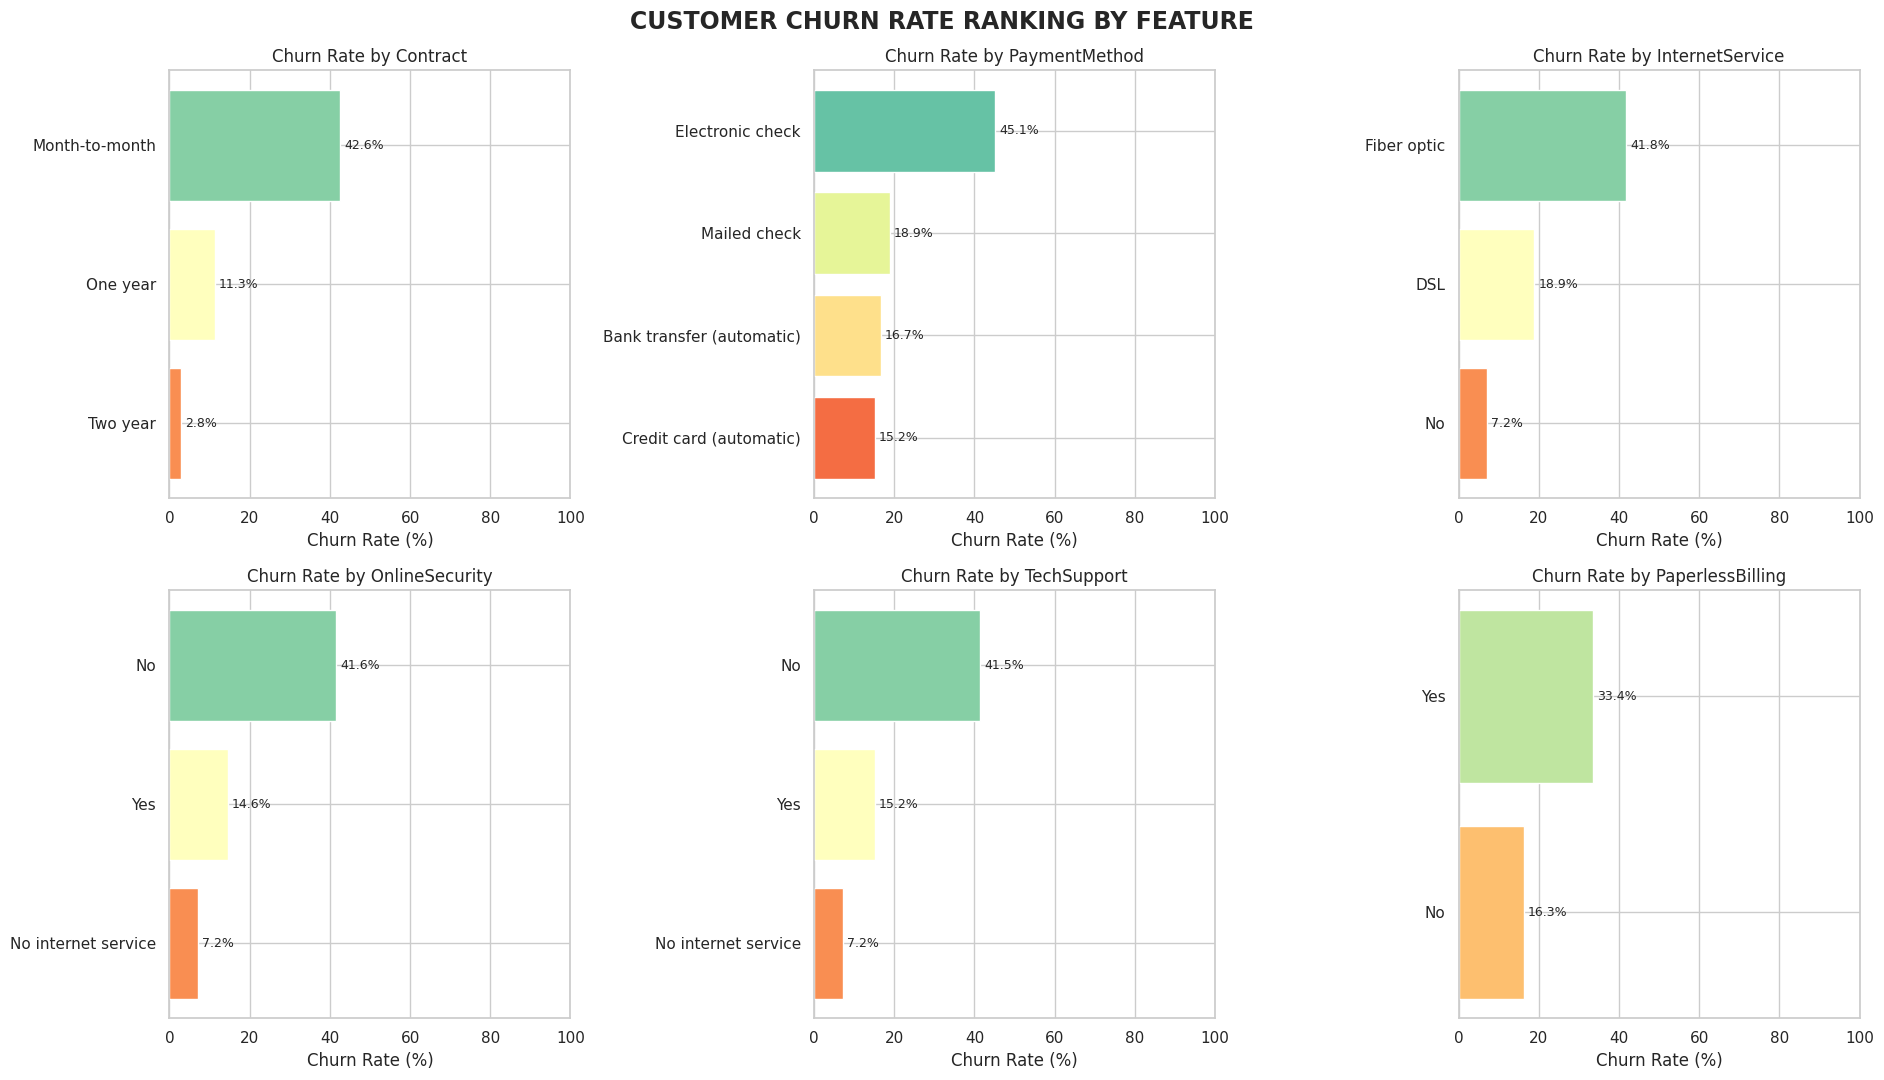


AUTOMATED CUSTOMER CHURN INSIGHTS

1. Total customers: 7,021
2. Churned customers: 1,857
3. Retained customers: 5,164
4. Overall churn rate: 26.45%
5. Average tenure: 32.47 months
6. Average monthly charges: $64.85

AVERAGE CUSTOMER COMPARISON


,Churned Customers,Retained Customers
tenure,18.09,37.64
MonthlyCharges,74.60,61.34
TotalCharges,1541.38,2557.80



CHURN RATE BY CONTRACT


Contract
Month-to-month    42.64
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


CHURN RATE BY INTERNET SERVICE


InternetService
Fiber optic    41.78
DSL            18.89
No              7.21
Name: Churn, dtype: float64


CHURN RATE BY PAYMENT METHOD


PaymentMethod
Electronic check             45.15
Mailed check                 18.92
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64


INTERPRETATION
- Compare tenure and monthly charges between churn groups.
- Review contract types with higher observed churn rates.
- Compare service and payment categories for retention patterns.
- These are descriptive associations, not proof of causation.

ALL VISUALIZATIONS COMPLETED SUCCESSFULLY


In [13]:

# ================================================================
# TELCO CUSTOMER CHURN - COMPLETE DATA VISUALIZATION
# Uses all 20 columns | Multiple colors | Detailed EDA
# ================================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.ticker import FuncFormatter

# ------------------------------------------------
# 1. CONFIGURATION AND DATA PREPARATION
# ------------------------------------------------

if "df" not in globals():
    raise NameError(
        "Dataset not found. Load your CSV first using "
        "df = pd.read_csv('/path/to/your_file.csv')"
    )

data = df.copy()

expected_columns = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod',
    'MonthlyCharges', 'TotalCharges', 'Churn'
]

missing_columns = [
    col for col in expected_columns if col not in data.columns
]

if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")

data = data[expected_columns].copy()

# Clean numeric columns
for col in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Remove duplicate records
data = data.drop_duplicates().reset_index(drop=True)

# Remove rows without a churn target
data = data.dropna(subset=['Churn']).copy()

# Remove accidental whitespace from categorical values
for col in data.select_dtypes(include=['object', 'string']).columns:
    data[col] = data[col].str.strip()

# Treat blank TotalCharges values as missing
data['TotalCharges'] = data['TotalCharges'].fillna(
    data['TotalCharges'].median()
)

# Convert SeniorCitizen to readable labels for visualization
data['SeniorCitizenLabel'] = data['SeniorCitizen'].map({
    0: 'Non-Senior',
    1: 'Senior'
}).fillna(data['SeniorCitizen'].astype(str))

# Consistent, colorful visual theme
sns.set_theme(style="whitegrid", context="notebook")

palette = [
    '#4361EE', '#F72585', '#4CC9F0', '#7209B7',
    '#F77F00', '#2A9D8F', '#E63946', '#90BE6D',
    '#FFBE0B', '#8338EC', '#3A86FF', '#FB5607'
]

binary_palette = {
    'Yes': '#F72585',
    'No': '#4361EE',
    'Female': '#F72585',
    'Male': '#4361EE',
    'Month-to-month': '#F77F00',
    'One year': '#4361EE',
    'Two year': '#2A9D8F'
}

print("=" * 70)
print("TELCO CUSTOMER CHURN - EXPLORATORY DATA ANALYSIS")
print("=" * 70)
print(f"Dataset shape: {data.shape}")
print(f"Total customers: {len(data):,}")
print(f"Duplicate rows removed: {df[expected_columns].duplicated().sum():,}")
print("\nMissing values after cleaning:")
print(data[expected_columns].isnull().sum())
print("\nChurn distribution:")
print(data['Churn'].value_counts(dropna=False))

# ------------------------------------------------
# 2. DATASET OVERVIEW AND SUMMARY
# ------------------------------------------------

print("\nNUMERICAL SUMMARY")
display(data[['tenure', 'MonthlyCharges', 'TotalCharges']].describe().round(2))

print("\nCATEGORICAL SUMMARY")
display(data[expected_columns].describe(include='object').T)

# ------------------------------------------------
# 3. KPI DASHBOARD
# ------------------------------------------------

total_customers = len(data)
churn_count = (data['Churn'] == 'Yes').sum()
retained_count = (data['Churn'] == 'No').sum()
churn_rate = 100 * churn_count / total_customers if total_customers else 0
avg_monthly = data['MonthlyCharges'].mean()
avg_tenure = data['tenure'].mean()

fig, axes = plt.subplots(1, 5, figsize=(19, 4))
fig.suptitle("TELCO CUSTOMER CHURN — KEY PERFORMANCE INDICATORS",
             fontsize=16, fontweight='bold', y=1.06)

kpis = [
    ("Total Customers", f"{total_customers:,}", '#4361EE'),
    ("Churned", f"{churn_count:,}", '#F72585'),
    ("Retained", f"{retained_count:,}", '#2A9D8F'),
    ("Churn Rate", f"{churn_rate:.2f}%", '#F77F00'),
    ("Avg Monthly Charges", f"${avg_monthly:.2f}", '#7209B7')
]

for ax, (label, value, color) in zip(axes, kpis):
    ax.set_facecolor('#F8F9FA')
    ax.text(0.5, 0.62, value, ha='center', va='center',
            fontsize=19, fontweight='bold', color=color,
            transform=ax.transAxes)
    ax.text(0.5, 0.30, label, ha='center', va='center',
            fontsize=10, color='#343A40', transform=ax.transAxes)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color(color)
        spine.set_linewidth(2)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 4. CHURN DISTRIBUTION
# ------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("CUSTOMER CHURN DISTRIBUTION",
             fontsize=16, fontweight='bold')

churn_counts = data['Churn'].value_counts()
churn_colors = ['#4361EE' if x == 'No' else '#F72585'
                for x in churn_counts.index]

sns.countplot(data=data, x='Churn', hue='Churn',
              palette={'No': '#4361EE', 'Yes': '#F72585'},
              legend=False, ax=axes[0])
axes[0].set_title("Number of Customers")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Customer Count")

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=3)

axes[1].pie(
    churn_counts.values,
    labels=churn_counts.index,
    colors=churn_colors,
    autopct='%1.1f%%',
    startangle=90,
    explode=[0.04] * len(churn_counts),
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
axes[1].set_title("Churn Percentage")

axes[2].bar(
    ['Churn Rate'],
    [churn_rate],
    color='#F72585',
    width=0.5
)
axes[2].bar_label(axes[2].containers[0], fmt='%.2f%%', padding=4)
axes[2].set_ylim(0, 100)
axes[2].set_ylabel("Percentage")
axes[2].set_title("Overall Churn Rate")

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 5. CUSTOMER DEMOGRAPHICS
# ------------------------------------------------

demographic_cols = [
    'gender', 'SeniorCitizenLabel', 'Partner', 'Dependents'
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("CUSTOMER DEMOGRAPHICS",
             fontsize=16, fontweight='bold')

for ax, col in zip(axes.flat, demographic_cols):
    counts = data[col].value_counts()
    colors = sns.color_palette("Set2", n_colors=len(counts))

    sns.countplot(
        data=data, x=col, hue=col, order=counts.index,
        palette=dict(zip(counts.index, colors)),
        legend=False, ax=ax
    )
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Customers")
    ax.tick_params(axis='x', rotation=15)

    for container in ax.containers:
        ax.bar_label(container, fmt='%d', padding=2)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 6. DEMOGRAPHICS VS CHURN
# ------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("DEMOGRAPHICS VS CUSTOMER CHURN",
             fontsize=16, fontweight='bold')

for ax, col in zip(axes.flat, demographic_cols):
    churn_pct = pd.crosstab(
        data[col], data['Churn'], normalize='index'
    ).mul(100)

    churn_pct.plot(
        kind='bar',
        stacked=True,
        ax=ax,
        color=['#4361EE', '#F72585'],
        edgecolor='white'
    )

    ax.set_title(f"Churn Percentage by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Percentage of Customers")
    ax.set_ylim(0, 100)
    ax.legend(title='Churn', loc='upper right')
    ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 7. NUMERICAL DISTRIBUTIONS
# ------------------------------------------------

numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("NUMERICAL FEATURE DISTRIBUTIONS",
             fontsize=16, fontweight='bold')

hist_colors = ['#4361EE', '#F72585', '#2A9D8F']

for i, col in enumerate(numeric_cols):
    sns.histplot(
        data=data, x=col, kde=True, bins=30,
        color=hist_colors[i], ax=axes[0, i]
    )
    axes[0, i].set_title(f"Distribution of {col}")
    axes[0, i].set_ylabel("Frequency")

    sns.boxplot(
        data=data, x='Churn', y=col,
        hue='Churn',
        palette={'No': '#4361EE', 'Yes': '#F72585'},
        legend=False, ax=axes[1, i]
    )
    axes[1, i].set_title(f"{col} by Churn")
    axes[1, i].set_xlabel("Churn")

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 8. TENURE ANALYSIS
# ------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
fig.suptitle("CUSTOMER TENURE ANALYSIS",
             fontsize=16, fontweight='bold')

sns.histplot(
    data=data, x='tenure', hue='Churn',
    bins=30, multiple='stack',
    palette={'No': '#4361EE', 'Yes': '#F72585'},
    ax=axes[0]
)
axes[0].set_title("Tenure Distribution by Churn")
axes[0].set_xlabel("Tenure (Months)")

sns.violinplot(
    data=data, x='Churn', y='tenure',
    hue='Churn',
    palette={'No': '#4361EE', 'Yes': '#F72585'},
    legend=False, inner='quartile', ax=axes[1]
)
axes[1].set_title("Tenure Spread by Churn")

tenure_bins = [-1, 12, 24, 36, 48, 60, 72]
tenure_labels = [
    '0–12', '13–24', '25–36',
    '37–48', '49–60', '61–72'
]

data['TenureGroup'] = pd.cut(
    data['tenure'],
    bins=tenure_bins,
    labels=tenure_labels
)

tenure_churn = data.groupby(
    'TenureGroup', observed=False
)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100)

axes[2].bar(
    tenure_churn.index.astype(str),
    tenure_churn.values,
    color=sns.color_palette("Spectral", len(tenure_churn))
)
axes[2].set_title("Churn Rate by Tenure Group")
axes[2].set_xlabel("Tenure (Months)")
axes[2].set_ylabel("Churn Rate (%)")
axes[2].tick_params(axis='x', rotation=25)

for container in axes[2].containers:
    axes[2].bar_label(container, fmt='%.1f%%', padding=2)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 9. MONTHLY CHARGES ANALYSIS
# ------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
fig.suptitle("MONTHLY CHARGES ANALYSIS",
             fontsize=16, fontweight='bold')

sns.histplot(
    data=data, x='MonthlyCharges',
    hue='Churn', kde=True, element='step',
    palette={'No': '#4361EE', 'Yes': '#F72585'},
    ax=axes[0]
)
axes[0].set_title("Monthly Charges by Churn")

sns.boxplot(
    data=data, x='Churn', y='MonthlyCharges',
    hue='Churn',
    palette={'No': '#4361EE', 'Yes': '#F72585'},
    legend=False, ax=axes[1]
)
axes[1].set_title("Monthly Charges Comparison")

sns.scatterplot(
    data=data, x='tenure', y='MonthlyCharges',
    hue='Churn',
    palette={'No': '#4361EE', 'Yes': '#F72585'},
    alpha=0.65, s=35, ax=axes[2]
)
axes[2].set_title("Tenure vs Monthly Charges")

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 10. TOTAL CHARGES ANALYSIS
# ------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle("TOTAL CHARGES ANALYSIS",
             fontsize=16, fontweight='bold')

sns.histplot(
    data=data, x='TotalCharges',
    hue='Churn', kde=True, bins=35,
    palette={'No': '#4361EE', 'Yes': '#F72585'},
    ax=axes[0]
)
axes[0].set_title("Total Charges Distribution")

sns.scatterplot(
    data=data, x='tenure', y='TotalCharges',
    hue='Churn',
    palette={'No': '#4361EE', 'Yes': '#F72585'},
    alpha=0.6, ax=axes[1]
)
axes[1].set_title("Tenure vs Total Charges")

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 11. SERVICE SUBSCRIPTION DISTRIBUTIONS
# ------------------------------------------------

service_cols = [
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]

fig, axes = plt.subplots(3, 3, figsize=(19, 15))
fig.suptitle("CUSTOMER SERVICE SUBSCRIPTIONS",
             fontsize=17, fontweight='bold')

for i, col in enumerate(service_cols):
    ax = axes.flat[i]
    counts = data[col].value_counts()
    colors = sns.color_palette("husl", n_colors=len(counts))

    sns.barplot(
        x=counts.index.astype(str),
        y=counts.values,
        hue=counts.index.astype(str),
        palette=dict(zip(counts.index.astype(str), colors)),
        legend=False, ax=ax
    )

    ax.set_title(f"{col} Distribution")
    ax.set_xlabel(col)
    ax.set_ylabel("Customers")
    ax.tick_params(axis='x', rotation=20)

    for container in ax.containers:
        ax.bar_label(container, fmt='%.0f', padding=2)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 12. SERVICE SUBSCRIPTIONS VS CHURN
# ------------------------------------------------

fig, axes = plt.subplots(3, 3, figsize=(19, 15))
fig.suptitle("SERVICE SUBSCRIPTIONS VS CHURN",
             fontsize=17, fontweight='bold')

for ax, col in zip(axes.flat, service_cols):
    churn_pct = pd.crosstab(
        data[col], data['Churn'], normalize='index'
    ).mul(100)

    churn_pct.plot(
        kind='bar',
        stacked=True,
        color=['#4361EE', '#F72585'],
        edgecolor='white',
        ax=ax
    )

    ax.set_title(f"{col} vs Churn")
    ax.set_xlabel(col)
    ax.set_ylabel("Percentage")
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=20)
    ax.legend(title='Churn', fontsize=8)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 13. CONTRACT, BILLING AND PAYMENT ANALYSIS
# ------------------------------------------------

business_cols = [
    'Contract', 'PaperlessBilling', 'PaymentMethod'
]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("CONTRACT, BILLING AND PAYMENT DISTRIBUTIONS",
             fontsize=16, fontweight='bold')

for ax, col in zip(axes, business_cols):
    counts = data[col].value_counts()
    colors = sns.color_palette("Set1", n_colors=len(counts))

    sns.barplot(
        x=counts.index.astype(str),
        y=counts.values,
        hue=counts.index.astype(str),
        palette=dict(zip(counts.index.astype(str), colors)),
        legend=False, ax=ax
    )
    ax.set_title(f"{col} Distribution")
    ax.set_ylabel("Customers")
    ax.tick_params(axis='x', rotation=25)

    for container in ax.containers:
        ax.bar_label(container, fmt='%.0f', padding=2)

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 14. CONTRACT AND PAYMENT VS CHURN
# ------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("CONTRACT AND PAYMENT BEHAVIOUR VS CHURN",
             fontsize=16, fontweight='bold')

for ax, col in zip(axes, business_cols):
    churn_pct = pd.crosstab(
        data[col], data['Churn'], normalize='index'
    ).mul(100)

    churn_pct.plot(
        kind='bar',
        stacked=True,
        color=['#4361EE', '#F72585'],
        edgecolor='white',
        ax=ax
    )

    ax.set_title(f"Churn by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Percentage")
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=25)
    ax.legend(title='Churn')

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 15. NUMERICAL CORRELATION HEATMAP
# ------------------------------------------------

numeric_data = data[
    ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
].copy()

numeric_data['ChurnEncoded'] = (
    data['Churn'].map({'No': 0, 'Yes': 1})
)

correlation = numeric_data.corr(numeric_only=True)

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='RdYlBu_r',
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=1,
    square=True,
    cbar_kws={'label': 'Correlation Coefficient'}
)
plt.title("NUMERICAL CORRELATION HEATMAP",
          fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 16. CATEGORICAL CHURN RATE HEATMAP
# ------------------------------------------------

categorical_cols = [
    'gender', 'SeniorCitizenLabel', 'Partner', 'Dependents',
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod'
]

churn_rates = {}

for col in categorical_cols:
    churn_rates[col] = data.groupby(
        col, observed=False
    )['Churn'].apply(lambda s: (s == 'Yes').mean() * 100)

heatmap_data = pd.DataFrame(churn_rates).T
heatmap_data = heatmap_data.reindex(
    columns=sorted(heatmap_data.columns.astype(str))
)

plt.figure(figsize=(16, 10))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    linewidths=0.6,
    cbar_kws={'label': 'Churn Rate (%)'}
)
plt.title("CHURN RATE BY CATEGORY — HEATMAP",
          fontsize=16, fontweight='bold')
plt.xlabel("Category")
plt.ylabel("Customer Feature")
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 17. CUSTOMER RETENTION AND CHURN PROFILE
# ------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
fig.suptitle("CHURNED VS RETAINED CUSTOMER PROFILE",
             fontsize=16, fontweight='bold')

profile = data.groupby('Churn')[
    ['tenure', 'MonthlyCharges', 'TotalCharges']
].mean().T

profile.plot(
    kind='bar',
    color=['#4361EE', '#F72585'],
    edgecolor='white',
    ax=axes[0]
)
axes[0].set_title("Average Customer Metrics")
axes[0].set_ylabel("Average Value")
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend(title='Churn')

sns.boxplot(
    data=data, x='Churn', y='tenure',
    hue='Churn',
    palette={'No': '#4361EE', 'Yes': '#F72585'},
    legend=False, ax=axes[1]
)
axes[1].set_title("Customer Tenure Comparison")

sns.boxplot(
    data=data, x='Churn', y='MonthlyCharges',
    hue='Churn',
    palette={'No': '#4361EE', 'Yes': '#F72585'},
    legend=False, ax=axes[2]
)
axes[2].set_title("Monthly Charges Comparison")

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 18. MONTHLY CHARGES BY CONTRACT
# ------------------------------------------------

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=data,
    x='Contract',
    y='MonthlyCharges',
    hue='Contract',
    palette='Set2',
    legend=False
)
plt.title("MONTHLY CHARGES BY CONTRACT TYPE",
          fontsize=15, fontweight='bold')
plt.xlabel("Contract Type")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 19. TENURE VS TOTAL CHARGES BY CHURN
# ------------------------------------------------

plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=data,
    x='tenure',
    y='TotalCharges',
    hue='Churn',
    size='MonthlyCharges',
    sizes=(20, 150),
    alpha=0.65,
    palette={'No': '#4361EE', 'Yes': '#F72585'}
)
plt.title("TENURE, TOTAL CHARGES AND CHURN",
          fontsize=15, fontweight='bold')
plt.xlabel("Tenure (Months)")
plt.ylabel("Total Charges")
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 20. CUSTOMER CHURN RATE RANKING
# ------------------------------------------------

ranking_cols = [
    'Contract', 'PaymentMethod', 'InternetService',
    'OnlineSecurity', 'TechSupport', 'PaperlessBilling'
]

fig, axes = plt.subplots(2, 3, figsize=(19, 11))
fig.suptitle("CUSTOMER CHURN RATE RANKING BY FEATURE",
             fontsize=17, fontweight='bold')

for ax, col in zip(axes.flat, ranking_cols):
    rate = data.groupby(
        col, observed=False
    )['Churn'].apply(lambda s: (s == 'Yes').mean() * 100)

    rate = rate.sort_values(ascending=True)

    bars = ax.barh(
        rate.index.astype(str),
        rate.values,
        color=sns.color_palette("Spectral", n_colors=len(rate))
    )

    ax.set_title(f"Churn Rate by {col}")
    ax.set_xlabel("Churn Rate (%)")
    ax.set_xlim(0, 100)

    for bar, value in zip(bars, rate.values):
        ax.text(
            min(value + 1, 96),
            bar.get_y() + bar.get_height() / 2,
            f'{value:.1f}%',
            va='center',
            fontsize=9
        )

plt.tight_layout()
plt.show()

# ------------------------------------------------
# 21. AUTOMATED CHURN INSIGHTS
# ------------------------------------------------

print("\n" + "=" * 70)
print("AUTOMATED CUSTOMER CHURN INSIGHTS")
print("=" * 70)

print(f"\n1. Total customers: {total_customers:,}")
print(f"2. Churned customers: {churn_count:,}")
print(f"3. Retained customers: {retained_count:,}")
print(f"4. Overall churn rate: {churn_rate:.2f}%")
print(f"5. Average tenure: {avg_tenure:.2f} months")
print(f"6. Average monthly charges: ${avg_monthly:.2f}")

if churn_count > 0:
    churned = data[data['Churn'] == 'Yes']
    retained = data[data['Churn'] == 'No']

    print("\nAVERAGE CUSTOMER COMPARISON")
    comparison = pd.DataFrame({
        'Churned Customers': churned[
            ['tenure', 'MonthlyCharges', 'TotalCharges']
        ].mean(),
        'Retained Customers': retained[
            ['tenure', 'MonthlyCharges', 'TotalCharges']
        ].mean()
    })
    display(comparison.round(2))

    print("\nCHURN RATE BY CONTRACT")
    contract_rates = data.groupby(
        'Contract', observed=False
    )['Churn'].apply(lambda s: (s == 'Yes').mean() * 100)
    display(contract_rates.sort_values(ascending=False).round(2))

    print("\nCHURN RATE BY INTERNET SERVICE")
    internet_rates = data.groupby(
        'InternetService', observed=False
    )['Churn'].apply(lambda s: (s == 'Yes').mean() * 100)
    display(internet_rates.sort_values(ascending=False).round(2))

    print("\nCHURN RATE BY PAYMENT METHOD")
    payment_rates = data.groupby(
        'PaymentMethod', observed=False
    )['Churn'].apply(lambda s: (s == 'Yes').mean() * 100)
    display(payment_rates.sort_values(ascending=False).round(2))

    print("\nINTERPRETATION")
    print("- Compare tenure and monthly charges between churn groups.")
    print("- Review contract types with higher observed churn rates.")
    print("- Compare service and payment categories for retention patterns.")
    print("- These are descriptive associations, not proof of causation.")

print("\n" + "=" * 70)
print("ALL VISUALIZATIONS COMPLETED SUCCESSFULLY")
print("=" * 70)


## Feature engineering

TELCO CUSTOMER CHURN - MACHINE LEARNING
Dataset shape: (7021, 20)
Duplicate rows removed: 22

Target distribution:
Churn
No     5164
Yes    1857
Name: count, dtype: int64

Target label encoding:
No -> 0
Yes -> 1

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

TRAIN-TEST SPLIT
--------------------------------------------------
Training records: 5616
Testing records: 1405
Number of features: 19

Training target distribution:
No     73.56
Yes    26.44
Name: proportion, dtype: float64

TRAINING: Logistic Regression
Accuracy  : 74.31%
Precision : 50.96%
Recall    : 78.76%
F1 Score  : 61.88%
ROC-AUC   : 83.84%
Log Loss  : 0.4946

TRAINING: K-Nearest Neighbors
Accuracy  : 74.88%
Precision : 52.87%
Rec

,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%),ROC-AUC (%),Log Loss
0,AdaBoost,80.000,65.636,51.344,57.617,84.199,0.506
1,Gradient Boosting,80.285,67.273,49.731,57.187,84.017,0.422
2,Logistic Regression,74.306,50.957,78.763,61.880,83.844,0.495
3,Random Forest,78.149,58.760,58.602,58.681,83.043,0.441
4,Extra Trees,77.509,56.573,64.785,60.401,82.564,0.462
5,Gaussian Naive Bayes,75.089,52.191,70.430,59.954,82.538,0.819
6,Support Vector Machine,75.160,52.158,74.731,61.436,82.148,0.446
7,Decision Tree,70.961,46.928,73.925,57.411,78.714,1.308
8,K-Nearest Neighbors,74.875,52.870,47.043,49.787,75.755,1.316


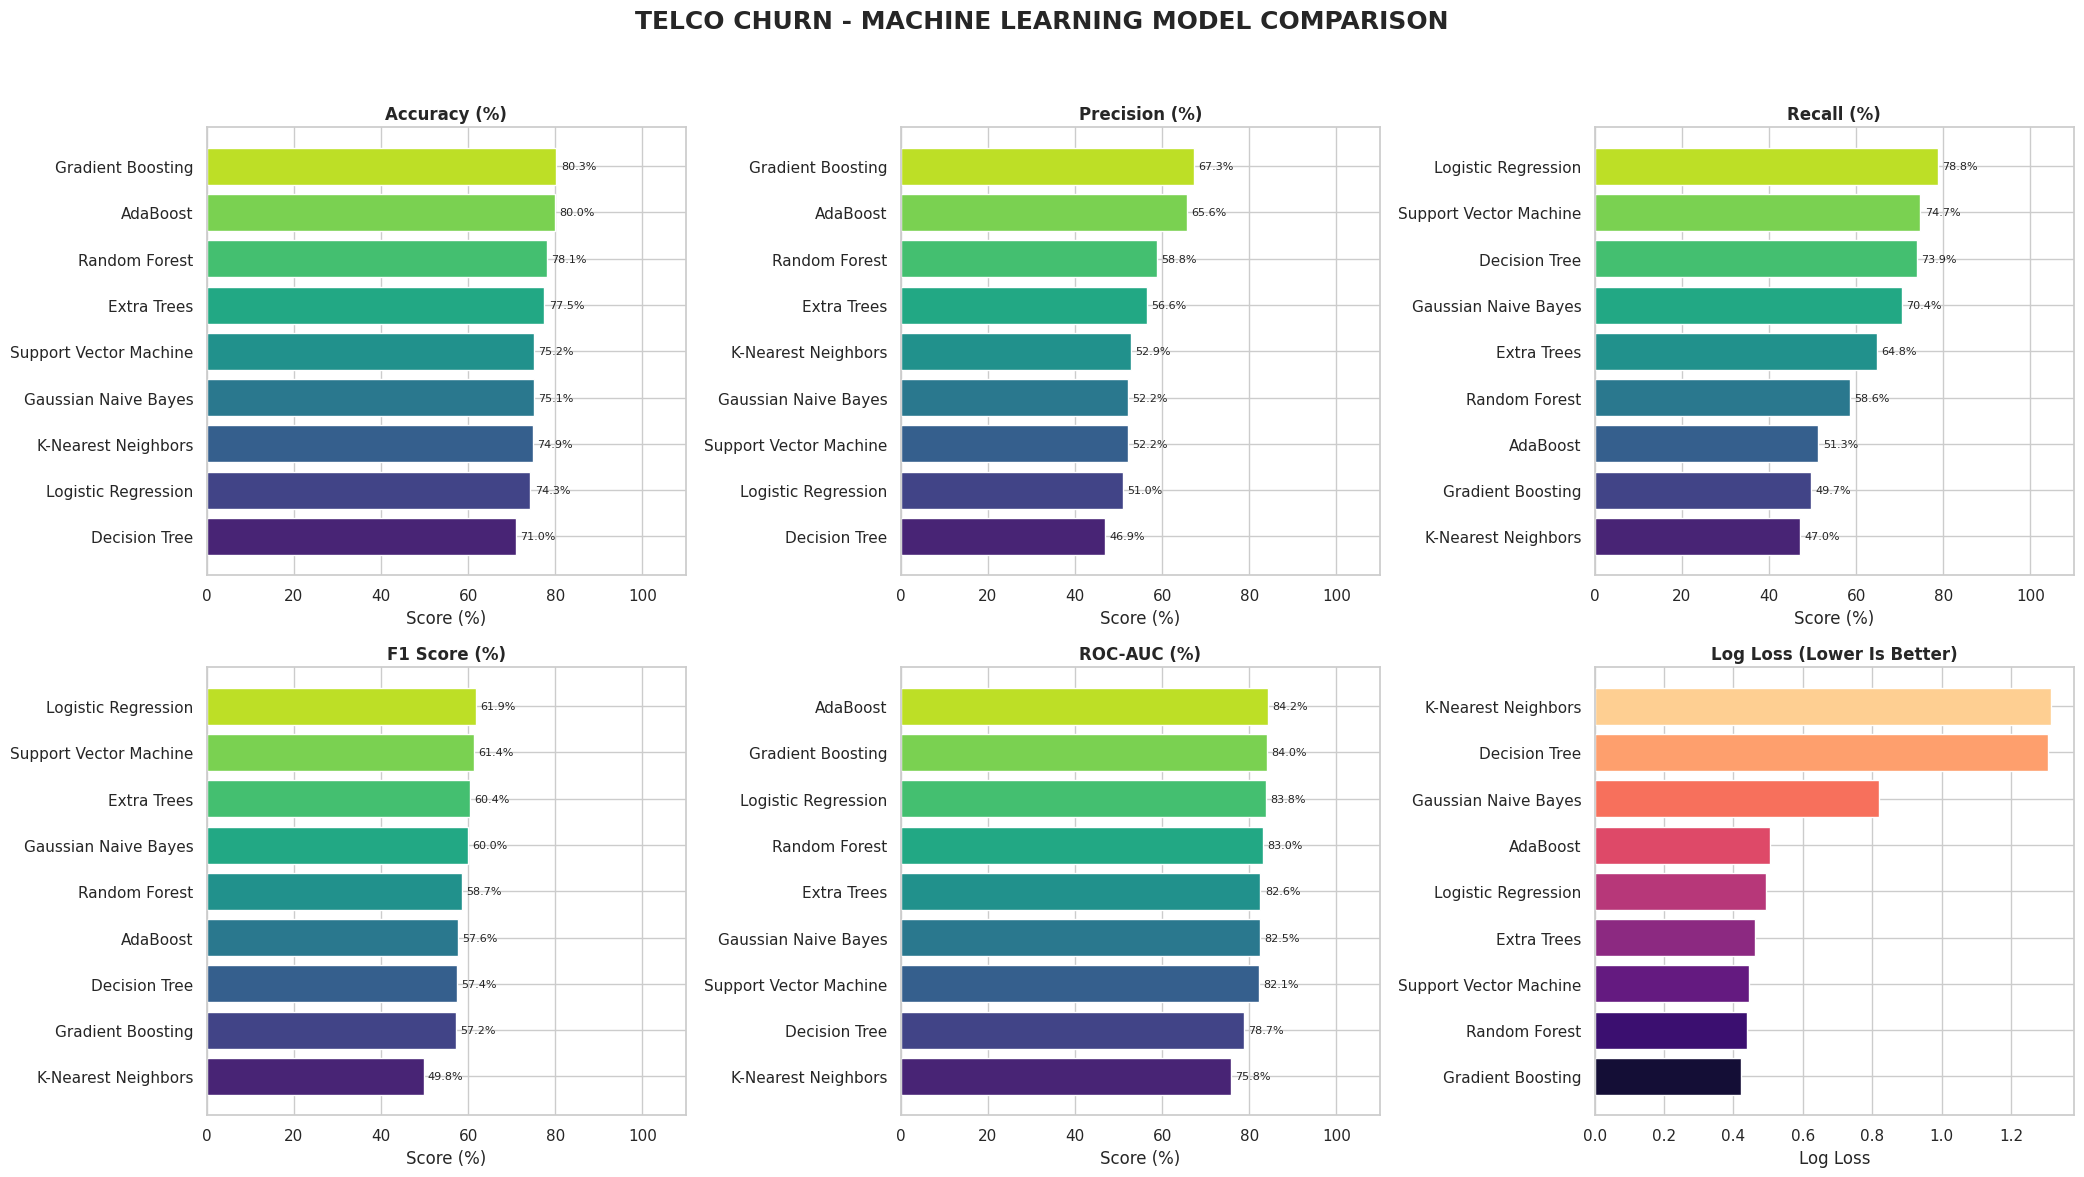

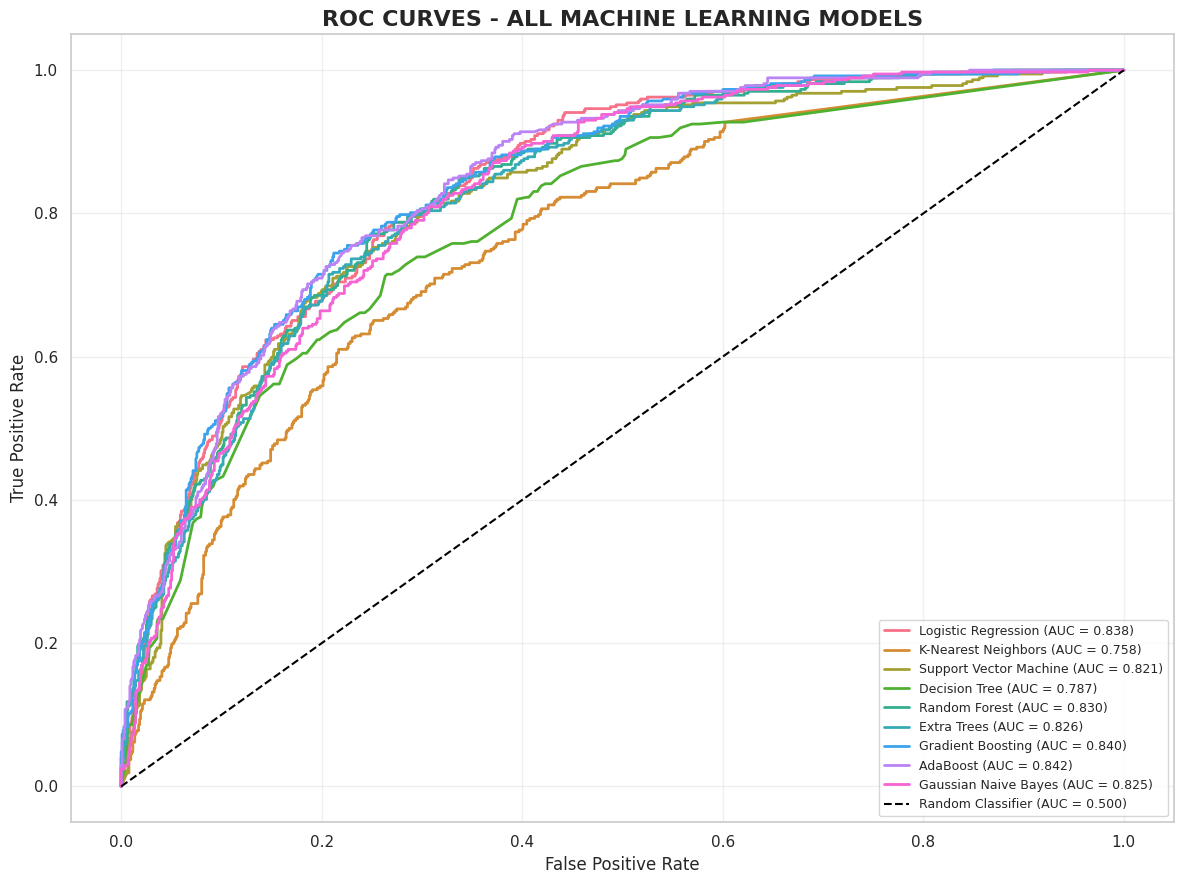


BEST MODEL BASED ON ROC-AUC
Best model: AdaBoost
Accuracy: 80.00%
ROC-AUC: 0.8420

CLASSIFICATION REPORT
---------------------------------------------------------------------------
              precision    recall  f1-score   support

          No       0.84      0.90      0.87      1033
         Yes       0.66      0.51      0.58       372

    accuracy                           0.80      1405
   macro avg       0.75      0.71      0.72      1405
weighted avg       0.79      0.80      0.79      1405



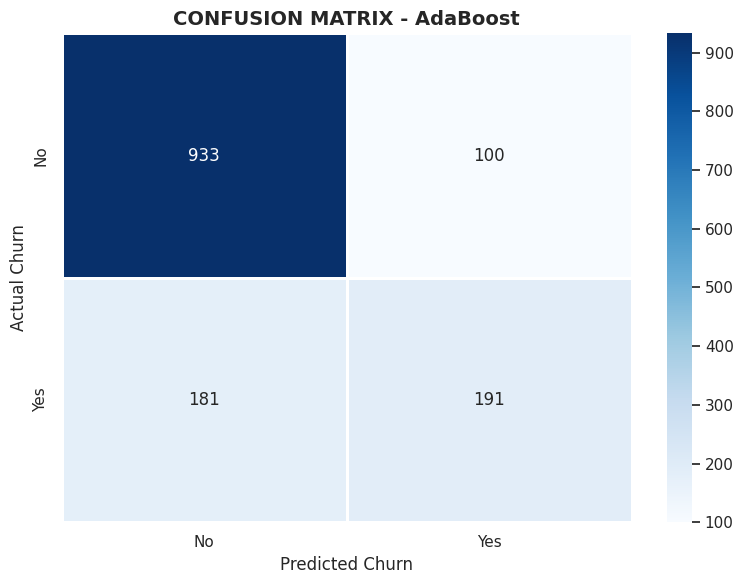

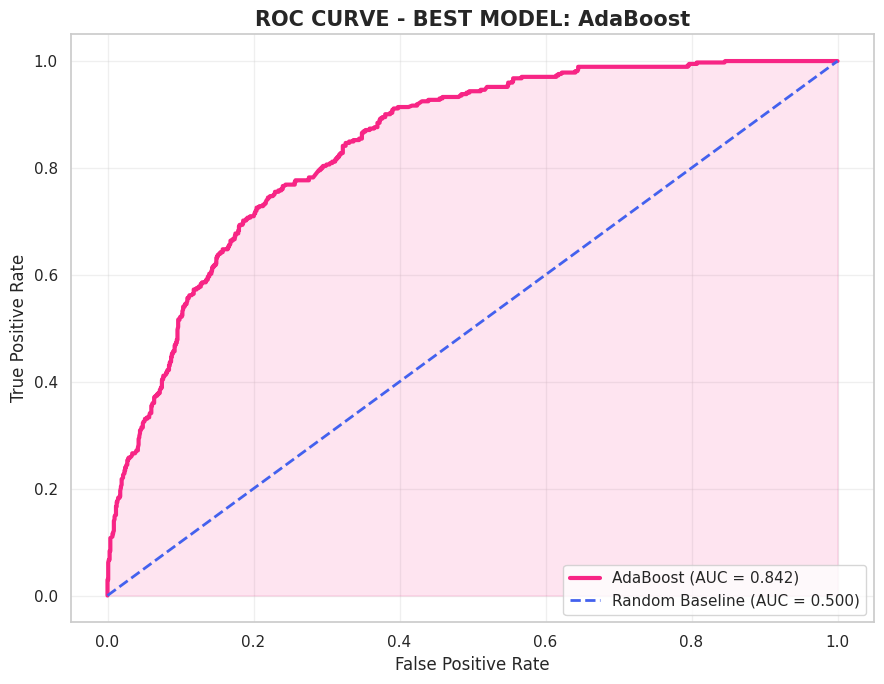


FEATURE IMPORTANCE
---------------------------------------------------------------------------


,Feature,Importance
16,Contract,0.2813
1,tenure,0.2359
2,MonthlyCharges,0.1630
10,OnlineSecurity,0.1148
13,TechSupport,0.0767
18,PaymentMethod,0.0382
3,TotalCharges,0.0203
17,PaperlessBilling,0.0190
11,OnlineBackup,0.0155
8,MultipleLines,0.0122


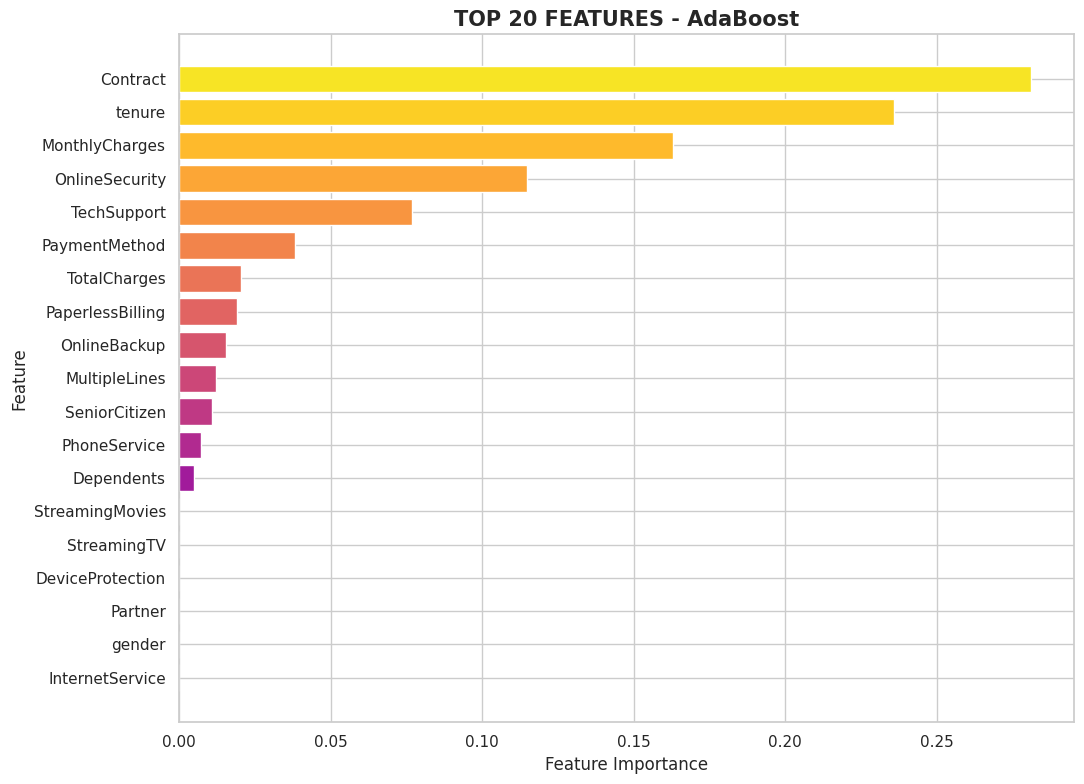


MACHINE LEARNING PIPELINE COMPLETED
Total original feature columns: 19
Training samples: 5616
Testing samples: 1405
Successful models: 9
Failed models: 0
Best model by ROC-AUC: AdaBoost
Best ROC-AUC: 0.8420
Best model accuracy: 80.00%

Note:
- ROC-AUC evaluates ranking ability across thresholds.
- Recall is important when identifying customers likely to churn.
- Compare precision and recall before choosing a deployment model.
- Test results are estimates, not a guarantee of future performance.


In [14]:

# =====================================================================
# TELCO CUSTOMER CHURN PREDICTION
# Complete ML Pipeline | Label Encoding | Train-Test Split | ROC-AUC
# Algorithms: Logistic Regression, KNN, SVM, Decision Tree,
# Random Forest, Extra Trees, Gradient Boosting, AdaBoost, Naive Bayes
# =====================================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    log_loss
)

# =====================================================================
# 1. LOAD AND VALIDATE DATA
# =====================================================================

if "df" not in globals():
    raise NameError(
        "Dataset not found. Load your dataset first:\n"
        "df = pd.read_csv('/path/to/your_dataset.csv')"
    )

data = df.copy()

expected_columns = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod',
    'MonthlyCharges', 'TotalCharges', 'Churn'
]

missing_columns = [
    col for col in expected_columns if col not in data.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

data = data[expected_columns].copy()

# Remove duplicate rows
before_duplicates = len(data)
data = data.drop_duplicates().reset_index(drop=True)
duplicates_removed = before_duplicates - len(data)

# Strip whitespace from text columns
for col in data.select_dtypes(include=['object', 'string']).columns:
    data[col] = data[col].str.strip()

# Convert numerical columns; invalid or blank values become NaN
for col in ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# The target must be present
data = data.dropna(subset=['Churn']).copy()

# Remove blank target labels
data = data[data['Churn'].astype(str).str.strip() != ''].copy()

# Validate target classes
if data['Churn'].nunique() != 2:
    raise ValueError(
        f"Expected exactly 2 Churn classes, found: "
        f"{data['Churn'].unique().tolist()}"
    )

print("=" * 75)
print("TELCO CUSTOMER CHURN - MACHINE LEARNING")
print("=" * 75)

print("Dataset shape:", data.shape)
print("Duplicate rows removed:", duplicates_removed)
print("\nTarget distribution:")
print(data['Churn'].value_counts())

# =====================================================================
# 2. DEFINE FEATURES AND TARGET
# =====================================================================

X = data.drop(columns=['Churn'])
y_original = data['Churn'].astype(str)

# Encode the target: No/Yes -> numeric class labels
target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y_original)

print("\nTarget label encoding:")
for class_value, encoded_value in zip(
    target_encoder.classes_,
    target_encoder.transform(target_encoder.classes_)
):
    print(f"{class_value} -> {encoded_value}")

# Identify feature types
categorical_features = X.select_dtypes(
    include=['object', 'string', 'category']
).columns.tolist()

numeric_features = X.select_dtypes(
    include=[np.number]
).columns.tolist()

print("\nCategorical features:", categorical_features)
print("\nNumeric features:", numeric_features)

# =====================================================================
# 3. TRAIN-TEST SPLIT
# =====================================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTRAIN-TEST SPLIT")
print("-" * 50)
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

print("\nTraining target distribution:")
print(pd.Series(
    target_encoder.inverse_transform(y_train)
).value_counts(normalize=True).mul(100).round(2))

# =====================================================================
# 4. LABEL ENCODING AND PREPROCESSING
# =====================================================================
# Categorical features use OrdinalEncoder inside the pipeline.
# Encoders and imputers are FIT ONLY on the training data.
# Unknown test categories receive -1 instead of causing an error.
#
# Note: Ordinal encoding assigns numbers to categories. One-hot encoding
# is often preferable for nominal categories in linear/distance models.

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numeric_pipeline, numeric_features),
        ('categorical', categorical_pipeline, categorical_features)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

# Scale the processed features for distance-based and linear models.
# Scaling also allows one common preprocessing pipeline for comparison.
# Tree-based models generally do not require scaling, but can still run.
full_preprocessor = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('scaler', StandardScaler())
])

# =====================================================================
# 5. DEFINE MACHINE LEARNING ALGORITHMS
# =====================================================================

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    ),

    'K-Nearest Neighbors': KNeighborsClassifier(
        n_neighbors=7,
        weights='distance'
    ),

    'Support Vector Machine': SVC(
        kernel='rbf',
        probability=True,
        class_weight='balanced',
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=5,
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight='balanced',
        n_jobs=-1,
        random_state=42
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        class_weight='balanced',
        n_jobs=-1,
        random_state=42
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ),

    'AdaBoost': AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    ),

    'Gaussian Naive Bayes': GaussianNB()
}

# =====================================================================
# 6. TRAIN MODELS AND EVALUATE
# =====================================================================

results = []
trained_models = {}
prediction_store = {}
probability_store = {}
failure_store = {}

for model_name, classifier in models.items():

    print("\n" + "=" * 75)
    print("TRAINING:", model_name)
    print("=" * 75)

    try:
        # Each model gets its own fitted preprocessing pipeline
        model_pipeline = Pipeline(steps=[
            ('preprocessor', full_preprocessor),
            ('classifier', classifier)
        ])

        # Train
        model_pipeline.fit(X_train, y_train)

        # Predict class labels
        y_pred = model_pipeline.predict(X_test)

        # Predict probability for positive class (Churn = Yes)
        positive_class_index = list(
            model_pipeline.named_steps['classifier'].classes_
        ).index(1)

        y_prob = model_pipeline.predict_proba(X_test)[
            :, positive_class_index
        ]

        # Calculate evaluation metrics
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(
            y_test, y_pred, zero_division=0
        )
        recall = recall_score(
            y_test, y_pred, zero_division=0
        )
        f1 = f1_score(
            y_test, y_pred, zero_division=0
        )
        auc = roc_auc_score(y_test, y_prob)
        loss = log_loss(
            y_test,
            model_pipeline.predict_proba(X_test),
            labels=model_pipeline.named_steps[
                'classifier'
            ].classes_
        )

        results.append({
            'Model': model_name,
            'Accuracy (%)': accuracy * 100,
            'Precision (%)': precision * 100,
            'Recall (%)': recall * 100,
            'F1 Score (%)': f1 * 100,
            'ROC-AUC (%)': auc * 100,
            'Log Loss': loss
        })

        trained_models[model_name] = model_pipeline
        prediction_store[model_name] = y_pred
        probability_store[model_name] = y_prob

        print(f"Accuracy  : {accuracy * 100:.2f}%")
        print(f"Precision : {precision * 100:.2f}%")
        print(f"Recall    : {recall * 100:.2f}%")
        print(f"F1 Score  : {f1 * 100:.2f}%")
        print(f"ROC-AUC   : {auc * 100:.2f}%")
        print(f"Log Loss  : {loss:.4f}")

    except Exception as error:
        failure_store[model_name] = str(error)
        print(f"Model failed: {error}")

# =====================================================================
# 7. MODEL COMPARISON TABLE
# =====================================================================

if not results:
    raise RuntimeError(
        "All models failed. Review the error messages printed above."
    )

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by='ROC-AUC (%)', ascending=False
).reset_index(drop=True)

print("\n" + "=" * 90)
print("FINAL MODEL COMPARISON")
print("=" * 90)

display(results_df.round(3))

if failure_store:
    print("\nModels that failed:")
    for name, error in failure_store.items():
        print(f"{name}: {error}")

# =====================================================================
# 8. VISUALIZE MODEL PERFORMANCE
# =====================================================================

sns.set_theme(style='whitegrid')

metric_columns = [
    'Accuracy (%)', 'Precision (%)',
    'Recall (%)', 'F1 Score (%)', 'ROC-AUC (%)'
]

fig, axes = plt.subplots(2, 3, figsize=(21, 12))
fig.suptitle(
    'TELCO CHURN - MACHINE LEARNING MODEL COMPARISON',
    fontsize=18,
    fontweight='bold'
)

colors = sns.color_palette('husl', n_colors=len(results_df))

for i, metric in enumerate(metric_columns):
    ax = axes.flat[i]

    ordered = results_df.sort_values(
        metric, ascending=True
    )

    bars = ax.barh(
        ordered['Model'],
        ordered[metric],
        color=sns.color_palette(
            'viridis', n_colors=len(ordered)
        )
    )

    ax.set_title(metric, fontweight='bold')
    ax.set_xlabel('Score (%)')
    ax.set_xlim(0, 110)

    for bar, value in zip(bars, ordered[metric]):
        ax.text(
            value + 1,
            bar.get_y() + bar.get_height() / 2,
            f'{value:.1f}%',
            va='center',
            fontsize=8
        )

# Log loss: lower is better
ax = axes.flat[5]
ordered_loss = results_df.sort_values(
    'Log Loss', ascending=True
)

ax.barh(
    ordered_loss['Model'],
    ordered_loss['Log Loss'],
    color=sns.color_palette('magma', n_colors=len(ordered_loss))
)
ax.set_title('Log Loss (Lower Is Better)', fontweight='bold')
ax.set_xlabel('Log Loss')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# =====================================================================
# 9. ROC CURVES FOR ALL SUCCESSFUL MODELS
# =====================================================================

plt.figure(figsize=(12, 9))

roc_colors = sns.color_palette(
    'husl', n_colors=len(trained_models)
)

for (model_name, y_prob), color in zip(
    probability_store.items(), roc_colors
):
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    auc_value = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        color=color,
        label=f'{model_name} (AUC = {auc_value:.3f})'
    )

# Random classifier baseline
plt.plot(
    [0, 1], [0, 1],
    linestyle='--',
    color='black',
    linewidth=1.5,
    label='Random Classifier (AUC = 0.500)'
)

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title(
    'ROC CURVES - ALL MACHINE LEARNING MODELS',
    fontsize=16,
    fontweight='bold'
)
plt.legend(loc='lower right', fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# =====================================================================
# 10. SELECT BEST MODEL BY ROC-AUC
# =====================================================================

best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
best_predictions = prediction_store[best_model_name]
best_probabilities = probability_store[best_model_name]

print("\n" + "=" * 75)
print("BEST MODEL BASED ON ROC-AUC")
print("=" * 75)

print("Best model:", best_model_name)
print(f"Accuracy: {accuracy_score(y_test, best_predictions) * 100:.2f}%")
print(f"ROC-AUC: {roc_auc_score(y_test, best_probabilities):.4f}")

# =====================================================================
# 11. BEST MODEL CLASSIFICATION REPORT
# =====================================================================

print("\nCLASSIFICATION REPORT")
print("-" * 75)

print(classification_report(
    y_test,
    best_predictions,
    labels=[0, 1],
    target_names=[
        str(target_encoder.inverse_transform([0])[0]),
        str(target_encoder.inverse_transform([1])[0])
    ],
    zero_division=0
))

# =====================================================================
# 12. BEST MODEL CONFUSION MATRIX
# =====================================================================

cm = confusion_matrix(
    y_test, best_predictions, labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=1,
    xticklabels=[
        target_encoder.inverse_transform([0])[0],
        target_encoder.inverse_transform([1])[0]
    ],
    yticklabels=[
        target_encoder.inverse_transform([0])[0],
        target_encoder.inverse_transform([1])[0]
    ]
)

plt.title(
    f'CONFUSION MATRIX - {best_model_name}',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Predicted Churn')
plt.ylabel('Actual Churn')
plt.tight_layout()
plt.show()

# =====================================================================
# 13. BEST MODEL ROC CURVE WITH AUC
# =====================================================================

fpr, tpr, thresholds = roc_curve(
    y_test, best_probabilities
)
best_auc = roc_auc_score(y_test, best_probabilities)

plt.figure(figsize=(9, 7))

plt.plot(
    fpr, tpr,
    color='#F72585',
    linewidth=3,
    label=f'{best_model_name} (AUC = {best_auc:.3f})'
)

plt.plot(
    [0, 1], [0, 1],
    color='#4361EE',
    linestyle='--',
    linewidth=2,
    label='Random Baseline (AUC = 0.500)'
)

plt.fill_between(
    fpr, tpr,
    alpha=0.12,
    color='#F72585'
)

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title(
    f'ROC CURVE - BEST MODEL: {best_model_name}',
    fontsize=15,
    fontweight='bold'
)
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# =====================================================================
# 14. OPTIONAL FEATURE IMPORTANCE
# =====================================================================
# Available for tree-based models only.

tree_models = [
    'Decision Tree', 'Random Forest',
    'Extra Trees', 'Gradient Boosting', 'AdaBoost'
]

importance_model_name = next(
    (name for name in results_df['Model']
     if name in tree_models),
    None
)

if importance_model_name is not None:

    fitted_pipeline = trained_models[importance_model_name]
    fitted_classifier = fitted_pipeline.named_steps['classifier']

    if hasattr(fitted_classifier, 'feature_importances_'):

        # Retrieve the actual processed feature names
        fitted_preprocessor = (
            fitted_pipeline.named_steps['preprocessor']
            .named_steps['preprocessing']
        )

        feature_names = fitted_preprocessor.get_feature_names_out()
        importances = fitted_classifier.feature_importances_

        feature_importance_df = pd.DataFrame({
            'Feature': feature_names,
            'Importance': importances
        }).sort_values(
            'Importance', ascending=False
        )

        print("\nFEATURE IMPORTANCE")
        print("-" * 75)
        display(feature_importance_df.head(20).round(4))

        top_features = feature_importance_df.head(20).sort_values(
            'Importance', ascending=True
        )

        plt.figure(figsize=(11, 8))
        plt.barh(
            top_features['Feature'],
            top_features['Importance'],
            color=sns.color_palette(
                'plasma', n_colors=len(top_features)
            )
        )
        plt.title(
            f'TOP 20 FEATURES - {importance_model_name}',
            fontsize=15,
            fontweight='bold'
        )
        plt.xlabel('Feature Importance')
        plt.ylabel('Feature')
        plt.tight_layout()
        plt.show()

# =====================================================================
# 15. FINAL SUMMARY
# =====================================================================

print("\n" + "=" * 75)
print("MACHINE LEARNING PIPELINE COMPLETED")
print("=" * 75)

print(f"Total original feature columns: {X.shape[1]}")
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Successful models: {len(trained_models)}")
print(f"Failed models: {len(failure_store)}")
print(f"Best model by ROC-AUC: {best_model_name}")
print(f"Best ROC-AUC: {best_auc:.4f}")
print(f"Best model accuracy: "
      f"{accuracy_score(y_test, best_predictions) * 100:.2f}%")

print("\nNote:")
print("- ROC-AUC evaluates ranking ability across thresholds.")
print("- Recall is important when identifying customers likely to churn.")
print("- Compare precision and recall before choosing a deployment model.")
print("- Test results are estimates, not a guarantee of future performance.")
print("=" * 75)


## Thank you..pls upvote!!!!